## Sección 1 - (Clasificación de variables y sus posibles valores)

1.1 - Obtener el excel con los datos

In [63]:
#!pip install wget

from wget import download
from os import path, listdir



if not path.exists("food_dataset.csv"):
  download("https://drive.google.com/uc?export=download&id=1IyK0jgDmyde9jdAT6hJFtjSWIYT3yaVz", "food_dataset.csv")

In [64]:
import pandas as pd

raw_dataset = pd.read_csv("food_dataset.csv")

print(raw_dataset.info())
raw_dataset.describe()

<class 'pandas.DataFrame'>
RangeIndex: 4997 entries, 0 to 4996
Data columns (total 24 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   product_name        4785 non-null   str    
 1   brands              4751 non-null   str    
 2   categories          4913 non-null   str    
 3   ingredients         4797 non-null   str    
 4   nutriscore_grade    4983 non-null   str    
 5   nova_group          4522 non-null   float64
 6   ecoscore_grade      4984 non-null   str    
 7   allergens           3332 non-null   str    
 8   energy_kcal         4682 non-null   float64
 9   fat_100g            4695 non-null   float64
 10  saturated_fat_100g  4617 non-null   float64
 11  carbs_100g          4676 non-null   float64
 12  sugars_100g         4631 non-null   float64
 13  fiber_100g          3495 non-null   float64
 14  proteins_100g       4690 non-null   float64
 15  salt_100g           4653 non-null   float64
 16  sodium_100g      

,nova_group,energy_kcal,fat_100g,saturated_fat_100g,carbs_100g,sugars_100g,fiber_100g,proteins_100g,salt_100g,sodium_100g
count,4522.000000,4682.000000,4695.000000,4617.000000,4676.000000,4631.000000,3.495000e+03,4690.000000,4653.000000,4653.000000
mean,3.278859,301.225402,15.997065,5.489583,32.598284,12.368927,1.748567e+09,7.348264,1.477237,0.590895
std,1.033540,221.661070,21.974815,12.451133,133.906873,22.020440,1.033727e+11,11.135688,14.776243,5.910491
min,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000
25%,3.000000,99.000000,1.500000,0.300000,4.800000,1.095000,5.000000e-01,1.700000,0.030000,0.012000
50%,4.000000,295.000000,7.420000,1.500000,19.700000,4.300000,3.000000e+00,6.300000,0.312000,0.125000
75%,4.000000,456.000000,23.000000,6.800000,58.000000,16.000000,6.600000e+00,9.600000,1.000000,0.400000
max,4.000000,5280.000000,554.000000,595.000000,8989.000000,895.000000,6.111242e+12,597.000000,898.000000,359.200000


Al visualizar el dataset nos percatamos de la cantidad de valores 'Branded/Packaged' que había en la variable food_type, así que decidimos mirar si es el único valor en la columna.

In [65]:
unique_values = raw_dataset["food_type"].unique()
print(unique_values)

<StringArray>
['Branded/Packaged']
Length: 1, dtype: str


1.2 - Al ver que no aporta información ya que tiene valor constante, decidimos eliminarla del dataset.

In [66]:
dataset = raw_dataset.drop(columns=["food_type"])

## Sección 2 - Análisis de nulos

2.1 - Obtenemos los valores nulos del dataset

In [67]:
dataset.isna().sum()

product_name           212
brands                 246
categories              84
ingredients            200
nutriscore_grade        14
nova_group             475
ecoscore_grade          13
allergens             1665
energy_kcal            315
fat_100g               302
saturated_fat_100g     380
carbs_100g             321
sugars_100g            366
fiber_100g            1502
proteins_100g          307
salt_100g              344
sodium_100g            344
contains_gluten          0
contains_dairy           0
contains_nuts            0
contains_soy             0
contains_eggs            0
contains_fish            0
dtype: int64

In [68]:
dataset['allergens'].value_counts()

allergens
en:milk                                                                                       695
en:gluten                                                                                     630
en:soybeans                                                                                   178
en:gluten, en:soybeans                                                                        131
en:gluten, en:milk                                                                            126
                                                                                             ... 
en:peanuts, en:soybeans, en:select-roasted-peanuts                                              1
en:gluten, en:suitable-for-vegans                                                               1
en:crustaceans, en:eggs, en:fish, en:gluten, en:milk, en:molluscs, en:mustard, en:soybeans      1
en:banana, en:nuts, en:sulphur-dioxide-and-sulphites                                            1
en:oatbran

Hay que tener cuidado con como se generan las booleanas a partir de los alérgenos. Muchos alérgenos son nulos, ¿significa que no tiene o que son desconocidos?

In [69]:
dataset['brands'].value_counts()

brands
Hacendado                                                                      149
Tesco                                                                           93
Bjorg                                                                           62
Jaouda                                                                          51
Gerblé                                                                          46
                                                                              ... 
Charbonnel et Walker, GINBIS, Mondelez, Oreo, Oreo - Mondelēz International      1
YoplaitYop                                                                       1
Champomy                                                                         1
La Baleine                                                                       1
Maître Prunille                                                                  1
Name: count, Length: 2063, dtype: int64

In [70]:
dataset['categories'].value_counts()

categories
en:plant-based-foods-and-beverages, en:plant-based-foods, en:cereals-and-potatoes            494
en:dairies, en:fermented-foods, en:fermented-milk-products                                   472
en:plant-based-foods-and-beverages, en:plant-based-foods, en:breakfasts                      351
en:snacks, en:sweet-snacks, en:biscuits-and-cakes                                            333
en:beverages-and-beverages-preparations, en:plant-based-foods-and-beverages, en:beverages    223
                                                                                            ... 
en:sweeteners, en:sugars, en:edulcorants-sucres-sucres-en-poudre                               1
en:seafood, en:fishes-and-their-products, en:breaded-products                                  1
en:dumplings, en:korean-dumplings, en:vegan                                                    1
en:beverages-and-beverages-preparations, en:beverages, en:canned-foods                         1
en:desserts, en:cho

Las categorías son difíciles de analizar en conjunto con otros datos por el modo en el que están estructuradas. Posibles alternativas: Multi-hot, agrupación en categorías más grandes.

In [71]:
dataset['ecoscore_grade'].value_counts()

ecoscore_grade
B                 895
A                 822
UNKNOWN           777
D                 716
C                 643
E                 508
NOT-APPLICABLE    259
A-PLUS            257
F                 107
Name: count, dtype: int64

2.2 - Tenemos 777 UNKNOWN en ecoscore y 259 NOT-APPLICABLE, si deseamos formular una hipótesis con el ecoscore, probablemente debamos tomar una parte del dataframe, descartando los ecoscore UNKNOWN.

In [72]:
dataset['ecoscore_grade'] = dataset['ecoscore_grade'].replace('UNKNOWN', pd.NA)

Eliminamos los UNKNOWN de ecoscore, mantenemos los NOT-APPLICABLE

In [73]:
dataset['energy_kcal'].value_counts()

energy_kcal
0.000000      104
900.000000     44
42.000000      36
400.000000     28
102.000000     28
             ... 
19.300000       1
0.700000        1
173.148148      1
325.000000      1
35.900000       1
Name: count, Length: 893, dtype: int64

In [74]:
dataset['ingredients'].value_counts()

ingredients
Eau minérale naturelle                                                                                                                                                                                                                                                                                                                                                                                                                 13
Milk                                                                                                                                                                                                                                                                                                                                                                                                                                    8
honey                                                                                                                                   

Ingredientes en mayúsculas y minúsculas, distintos idiomas. Algunos son más similares a etiquetas comerciales y otros simplemente ingredientes separados por coma.

In [75]:
dataset['nova_group'].value_counts()

nova_group
4.0    2637
3.0    1093
1.0     584
2.0     208
Name: count, dtype: int64

In [76]:
dataset['carbs_100g'].value_counts()

carbs_100g
0.000000     305
0.500000      87
11.000000     57
60.000000     52
4.800000      48
            ... 
19.600000      1
3.680000       1
60.300000      1
27.592593      1
63.400000      1
Name: count, Length: 784, dtype: int64

In [77]:
dataset['salt_100g'].value_counts()

salt_100g
0.00000    517
0.01000    202
0.03000    137
0.10000    130
1.00000    124
          ... 
0.61200      1
0.93200      1
0.02025      1
0.47600      1
4.40000      1
Name: count, Length: 825, dtype: int64

In [78]:
dataset['saturated_fat_100g'].value_counts()

saturated_fat_100g
0.000000     604
0.100000     268
0.200000     151
0.400000     144
0.300000     142
            ... 
1.530000       1
3.710000       1
0.010000       1
0.462963       1
14.600000      1
Name: count, Length: 529, dtype: int64

In [79]:
dataset['sugars_100g'].value_counts()

sugars_100g
0.000000     457
0.500000     201
1.000000      86
0.600000      72
0.700000      72
            ... 
13.680000      1
2.550000       1
3.796296       1
0.960000       1
9.330000       1
Name: count, Length: 681, dtype: int64

In [80]:
dataset['proteins_100g'].value_counts()

proteins_100g
0.000000     443
0.500000     147
10.000000    139
11.000000     91
12.000000     89
            ... 
5.640000       1
9.259259       1
0.380000       1
0.180000       1
4.880000       1
Name: count, Length: 514, dtype: int64

In [81]:
dataset['fat_100g'].value_counts()

fat_100g
0.000000     432
0.500000     159
0.100000      99
0.200000      71
1.500000      69
            ... 
0.100000       1
0.545000       1
3.518519       1
32.500000      1
24.400000      1
Name: count, Length: 693, dtype: int64

In [82]:
dataset['sodium_100g'].value_counts()

sodium_100g
0.0000    517
0.0040    202
0.0120    139
0.0400    131
0.4000    124
         ... 
0.0063      1
0.1250      1
0.2450      1
0.0081      1
1.7600      1
Name: count, Length: 772, dtype: int64

Aunque hay valores extremos imposibles, no podemos asegurar que los 0's en los valores cada 100g no sean validos sin tener contexto del producto.

Como la mayoría de los datos parecen ser válidos, no haremos imputación, eliminaremos valores ni agruparemos categorías hasta tener un objetivo claro de análisis.

## Sección 3 - ¿Filas duplicadas?

In [83]:
duplicados_exactos = dataset[dataset.duplicated(keep=False)]

print("Filas duplicadas:", dataset.duplicated().sum())

display(duplicados_exactos.sort_values("product_name"))

Filas duplicadas: 38


,product_name,brands,categories,ingredients,nutriscore_grade,nova_group,ecoscore_grade,allergens,energy_kcal,fat_100g,...,fiber_100g,proteins_100g,salt_100g,sodium_100g,contains_gluten,contains_dairy,contains_nuts,contains_soy,contains_eggs,contains_fish
904,Colman's Mustard,Colman's,"en:condiments, en:sauces, en:mustards","Water, MUSTARD flour (21%), sugar, salt, WHEAT...",E,4.0,A,"en:gluten, en:mustard",190.0,10.0,...,3.0,6.6,8.4,3.36,True,False,False,False,False,False
2497,Colman's Mustard,Colman's,"en:condiments, en:sauces, en:mustards","Water, MUSTARD flour (21%), sugar, salt, WHEAT...",E,4.0,A,"en:gluten, en:mustard",190.0,10.0,...,3.0,6.6,8.4,3.36,True,False,False,False,False,False
3543,Petits pains grilles,Carrefour,"en:plant-based-foods-and-beverages, en:plant-b...","Farine de _blé_ 46%, farine de _blé_ complet 4...",B,4.0,A,en:gluten,408.0,10.0,...,6.9,10.0,1.0,0.40,True,False,False,False,False,False
4025,Petits pains grilles,Carrefour,"en:plant-based-foods-and-beverages, en:plant-b...","Farine de _blé_ 46%, farine de _blé_ complet 4...",B,4.0,A,en:gluten,408.0,10.0,...,6.9,10.0,1.0,0.40,True,False,False,False,False,False
239,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,False,False,False,False,False,False
472,NaN,NaN,NaN,NaN,UNKNOWN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,False,False,False,False,False,False
892,NaN,NaN,"en:snacks, en:sweet-snacks, en:biscuits-and-cakes",NaN,UNKNOWN,NaN,C,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,False,False,False,False,False,False
1129,NaN,NaN,NaN,NaN,UNKNOWN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,False,False,False,False,False,False
1350,NaN,NaN,NaN,NaN,UNKNOWN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,False,False,False,False,False,False
1393,NaN,NaN,NaN,NaN,UNKNOWN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,False,False,False,False,False,False


3.1 - Existen 38 filas duplicadas, de las cuales tan solo 2 tienen valores reales, mientras las otras son valores NaN, eliminaremos todas las duplicadas.

In [84]:
filas_antes = len(dataset)

dataset = dataset.drop_duplicates().reset_index(drop=True)

print("Filas eliminadas:", filas_antes - len(dataset))
print("Filas restantes:", len(dataset))

Filas eliminadas: 38
Filas restantes: 4959


3.2 - Ahora analizamos los posibles duplicados que no sean exactos.

In [85]:
revision = dataset.copy()

for columna in ["product_name", "brands"]:
    revision[columna + "_normalizado"] = (
        revision[columna]
        .astype("string")
        .str.normalize("NFKC") # Sirve para carácteres especiales
        .str.strip()
        .str.lower()
        .str.replace(r"\s+", " ", regex=True)
        .replace("", pd.NA)
    )

claves = ["product_name_normalizado", "brands_normalizado"]

tiene_identificacion = revision[claves].notna().all(axis=1)

posibles_duplicados = revision.loc[ tiene_identificacion & revision.duplicated(subset=claves, keep=False)].sort_values(claves)

print("Filas con nombre y marca repetidos:", len(posibles_duplicados))

display(posibles_duplicados[
    ["product_name", "brands", "categories",
     "energy_kcal", "fat_100g", "carbs_100g",
     "proteins_100g", "ingredients"]
])

Filas con nombre y marca repetidos: 289


,product_name,brands,categories,energy_kcal,fat_100g,carbs_100g,proteins_100g,ingredients
1234,Almond,Plenish,"en:plant-based-foods-and-beverages, en:beverag...",26.0,2.200,0.4,0.90,"spring water, organic almonds 5%, sea salt"
1666,Almond,Plenish,"en:beverages-and-beverages-preparations, en:pl...",26.0,2.200,0.4,0.90,"Filtered water, _Almonds_ 6%, Sea salt"
74,BEANZ In a rich tomato sauce,HEINZ,"en:plant-based-foods-and-beverages, en:plant-b...",81.0,0.337,15.5,4.82,"Beans (50%), Tomatoes (36%), Water, Sugar, Mod..."
1686,Beanz in a rich tomato sauce,Heinz,"en:plant-based-foods-and-beverages, en:plant-b...",81.5,0.350,15.7,4.85,"Beans (50%), Tomatoes (36%), Water, Sugar, Spi..."
769,Bran Flakes,Kellogg's,"en:plant-based-foods-and-beverages, en:plant-b...",358.0,2.200,65.0,11.00,"Wholewheat (59%), wheat bran (18%), wholewheat..."
...,...,...,...,...,...,...,...,...
158,Weetabix,Weetabix,"en:plant-based-foods-and-beverages, en:plant-b...",340.0,2.000,65.0,11.20,"Wholegrain _Wheat_ (95%), Malted _Barley_ Extr..."
589,Weetabix,Weetabix,"en:plant-based-foods-and-beverages, en:plant-b...",349.0,2.050,66.7,11.50,"wholegrain _wheat_ (95%), malted _barley_ extr..."
1052,Weetabix,Weetabix,"en:plant-based-foods-and-beverages, en:plant-b...",362.0,2.000,69.0,12.00,"Wholegrain Wheat (95%), Malted Barley Extract,..."
432,Wholemeal Bread,Warburtons,"en:plant-based-foods-and-beverages, en:plant-b...",227.0,2.520,37.8,10.50,"Wholemeal Wheat Flour, Water, Yeast, Vegetable..."


La cantidad fue mayor de lo esperada. Descargaremos las filas para analizarlas manualmente.

In [86]:
#from google.colab import files

# posibles_duplicados.to_excel("posibles_duplicados.xlsx", index=False)

# files.download("posibles_duplicados.xlsx")

3.3 - Decidimos eliminar los registros considerados duplicados en base a el nombre, marca, alérgenos y una cota en la diferencia de valores nutricionales.

In [87]:
import pandas as pd
import numpy as np
import unicodedata
import re

trabajo = revision.copy()

nutrientes = [
    "energy_kcal", "fat_100g", "saturated_fat_100g",
    "carbs_100g", "sugars_100g", "fiber_100g",
    "proteins_100g", "salt_100g", "sodium_100g"
]

tolerancia_relativa = 0.05
# Habría que hacer una tolerancia para cada columna
tolerancias_absolutas = {columna: 1.5 for columna in nutrientes}


def normalizar_texto(valor):
    if pd.isna(valor):
        return None

    texto = unicodedata.normalize("NFKC", str(valor))
    texto = re.sub(r"\s+", " ", texto.strip().casefold())
    return texto or None


def normalizar_alergenos(valor):
    texto = normalizar_texto(valor)

    if texto is None:
        return None

    # Ignora el orden y los espacios. no traduce etiquetas!
    return tuple(sorted({
        etiqueta.strip()
        for etiqueta in texto.split(",")
        if etiqueta.strip()
    }))


# Las claves auxiliares no modifican las columnas originales.
claves = pd.DataFrame(index=trabajo.index)
claves["nombre"] = trabajo["product_name"].map(normalizar_texto)
claves["marca"] = trabajo["brands"].map(normalizar_texto)
claves["alergenos"] = trabajo["allergens"].map(normalizar_alergenos)

valores_nutricionales = trabajo[nutrientes].apply(
    pd.to_numeric, errors="raise"
)


def son_equivalentes(indice_a, indice_b):
    comparables = 0

    for columna in nutrientes:
        valor_a = valores_nutricionales.at[indice_a, columna]
        valor_b = valores_nutricionales.at[indice_b, columna]

        if pd.isna(valor_a) or pd.isna(valor_b):
            continue

        comparables += 1

        limite = max(tolerancias_absolutas[columna], tolerancia_relativa * max(abs(valor_a), abs(valor_b)))

        if abs(valor_a - valor_b) > limite:
            return False

    return comparables > 0




# Prioriza registros con más datos en las columnas originales.
columnas_originales = []

for columna in trabajo.columns:
    if not columna.endswith("_normalizado"):
        columnas_originales.append(columna)

datos_presentes = trabajo[columnas_originales].replace(r"^\s*$", np.nan, regex=True)
completitud = datos_presentes.notna().sum(axis=1)

# No agrupa registros sin nombre o marca.
identificacion_completa = claves[["nombre", "marca"]].notna().all(axis=1)

indices_eliminados = []
registro_eliminaciones = []

for _, grupo in claves.loc[identificacion_completa].groupby(["nombre", "marca"], sort=False, dropna=False):
    indices_ordenados = sorted( grupo.index, key=lambda indice: completitud.at[indice], reverse=True)

    grupos_equivalentes = []

    for indice in indices_ordenados:
        for grupo_equivalente in grupos_equivalentes:
            # Debe coincidir con todos los miembros
            if all(
                son_equivalentes(indice, otro)
                for otro in grupo_equivalente
            ):
                indice_conservado = grupo_equivalente[0]
                grupo_equivalente.append(indice)
                indices_eliminados.append(indice)

                registro_eliminaciones.append({
                  "indice_eliminado": indice,
                  "indice_conservado": indice_conservado,
                  "product_name": trabajo.at[indice, "product_name"],
                  "brands": trabajo.at[indice, "brands"],
                })
                break
        else:
            grupos_equivalentes.append([indice])


revision_limpia = trabajo.drop(index=indices_eliminados).copy()

registro_duplicados = pd.DataFrame(
    registro_eliminaciones,
    columns=[
        "indice_eliminado", "indice_conservado",
        "product_name", "brands"
    ]
)

print("Filas antes:", len(trabajo))
print("Filas eliminadas:", len(indices_eliminados))
print("Filas restantes:", len(revision_limpia))

display(registro_duplicados)

Filas antes: 4959
Filas eliminadas: 107
Filas restantes: 4852


,indice_eliminado,indice_conservado,product_name,brands
0,438,896,Nutella,Ferrero
1,2831,896,Nutella,Ferrero
2,2902,896,Nutella,Ferrero
3,23,896,Nutella,Ferrero
4,177,199,Nutella,"Ferrero,Nutella"
...,...,...,...,...
102,4207,3761,Special K Red Berries,Special K
103,4667,3947,Passata Sieved Tomatoes,Napolina
104,4577,4037,Tomato Ketchup,Tesco
105,4513,4165,Volvic zest citron,Volvic


## Sección 4 - Outliers

4.1 - Identificamos varios valores imposibles en las cantidades cada 100g desde el momento que vimos los máximos en el análisis inicial (por ejemplo, 9000g de carbohidratos por 100g de comida). Ahora nos encargaremos de invalidarlos.

In [88]:
revision_sin_invalidos = revision_limpia.copy()

nutrientes_100g = [
    "fat_100g", "saturated_fat_100g", "carbs_100g",
    "sugars_100g", "fiber_100g", "proteins_100g",
    "salt_100g", "sodium_100g"
]

registro_invalidos = []

for columna in nutrientes_100g:
    # Cantidades en gramos por 100 g: deben estar entre 0 y 100.
    valores = revision_sin_invalidos[columna]

    es_invalido = (valores.lt(0) | valores.gt(100))

    for indice in revision_sin_invalidos.index[es_invalido]:
        registro_invalidos.append({
            "indice": indice,
            "producto": revision_sin_invalidos.at[indice, "product_name"],
            "columna": columna,
            "valor_original": valores.at[indice],
        })

    revision_sin_invalidos.loc[es_invalido, columna] = np.nan

registro_invalidos = pd.DataFrame(
    registro_invalidos,
    columns=["indice", "producto", "columna", "valor_original"]
)

display(registro_invalidos)
print("Celdas invalidadas:", len(registro_invalidos))

,indice,producto,columna,valor_original
0,2420,NaN,fat_100g,5.540000e+02
1,2437,Havarti,fat_100g,1.400000e+02
2,2420,NaN,saturated_fat_100g,5.950000e+02
3,221,Sirop d'Agave,carbs_100g,1.150000e+02
4,2420,NaN,carbs_100g,8.989000e+03
5,221,Sirop d'Agave,sugars_100g,1.130000e+02
6,2420,NaN,sugars_100g,8.950000e+02
7,1420,Tartine et cuison,fiber_100g,5.120000e+02
8,2343,Jutos,fiber_100g,6.111242e+12
9,2420,NaN,fiber_100g,8.909000e+03


Celdas invalidadas: 14


4.2 - Identificamos outliers segun rango intercuartílico.

In [89]:
columnas_nutricionales = ["energy_kcal"] + nutrientes_100g
resumen_outliers = []

for columna in columnas_nutricionales:
    valores = revision_sin_invalidos[columna].dropna()

    if valores.empty:
        continue

    cuartil_1 = valores.quantile(0.25)
    cuartil_3 = valores.quantile(0.75)
    rango_intercuartil = cuartil_3 - cuartil_1

    limite_inferior = cuartil_1 - 1.5 * rango_intercuartil
    limite_superior = cuartil_3 + 1.5 * rango_intercuartil

    es_extremo = (
        valores.lt(limite_inferior)
        | valores.gt(limite_superior)
    )

    resumen_outliers.append({
        "columna": columna,
        "limite_inferior": limite_inferior,
        "limite_superior": limite_superior,
        "cantidad_extremos": int(es_extremo.sum())
    })

display(pd.DataFrame(resumen_outliers))

,columna,limite_inferior,limite_superior,cantidad_extremos
0,energy_kcal,-439.0000,993.0000,2
1,fat_100g,-30.7500,55.2500,250
2,saturated_fat_100g,-9.4500,16.5500,406
3,carbs_100g,-75.0000,137.8000,0
4,sugars_100g,-20.6000,37.0000,450
5,fiber_100g,-8.5450,15.5750,88
6,proteins_100g,-10.0050,21.4750,253
7,salt_100g,-1.3995,2.4125,227
8,sodium_100g,-0.5595,0.9645,228


In [90]:
casos_energia = revision_sin_invalidos.loc[
    revision_sin_invalidos["energy_kcal"] > 993,
    [
        "product_name", "brands", "categories",
        "energy_kcal", "fat_100g", "carbs_100g",
        "proteins_100g", "fiber_100g"
    ]
]

display(casos_energia)

,product_name,brands,categories,energy_kcal,fat_100g,carbs_100g,proteins_100g,fiber_100g
2437,Havarti,Hacendado,"en:dairies, en:fermented-foods, en:fermented-m...",1580.0,NaN,5.2,76.0,0.0
2676,Pizzarella premium,Gastro mixte,"en:dairies, en:fermented-foods, en:fermented-m...",5280.0,40.0,63.0,8.0,0.0


4.3 - No coinciden los valores nutricionales con los válidos, en pizzarella suman mas de 100g, y en Havarti hay 76g de proteina sin información de la grasa. Por ahora solo eliminaremos la información energética ya que supera los límites e introduce ruido en los gráficos iniciales.

In [91]:
revision_sin_invalidos.loc[
    casos_energia.index, "energy_kcal"
] = np.nan

## Sección 5 - Gráficos iniciales

5.1 - Realizamos una matriz de dispersión para comprender un poco mas las relaciones entre variables.

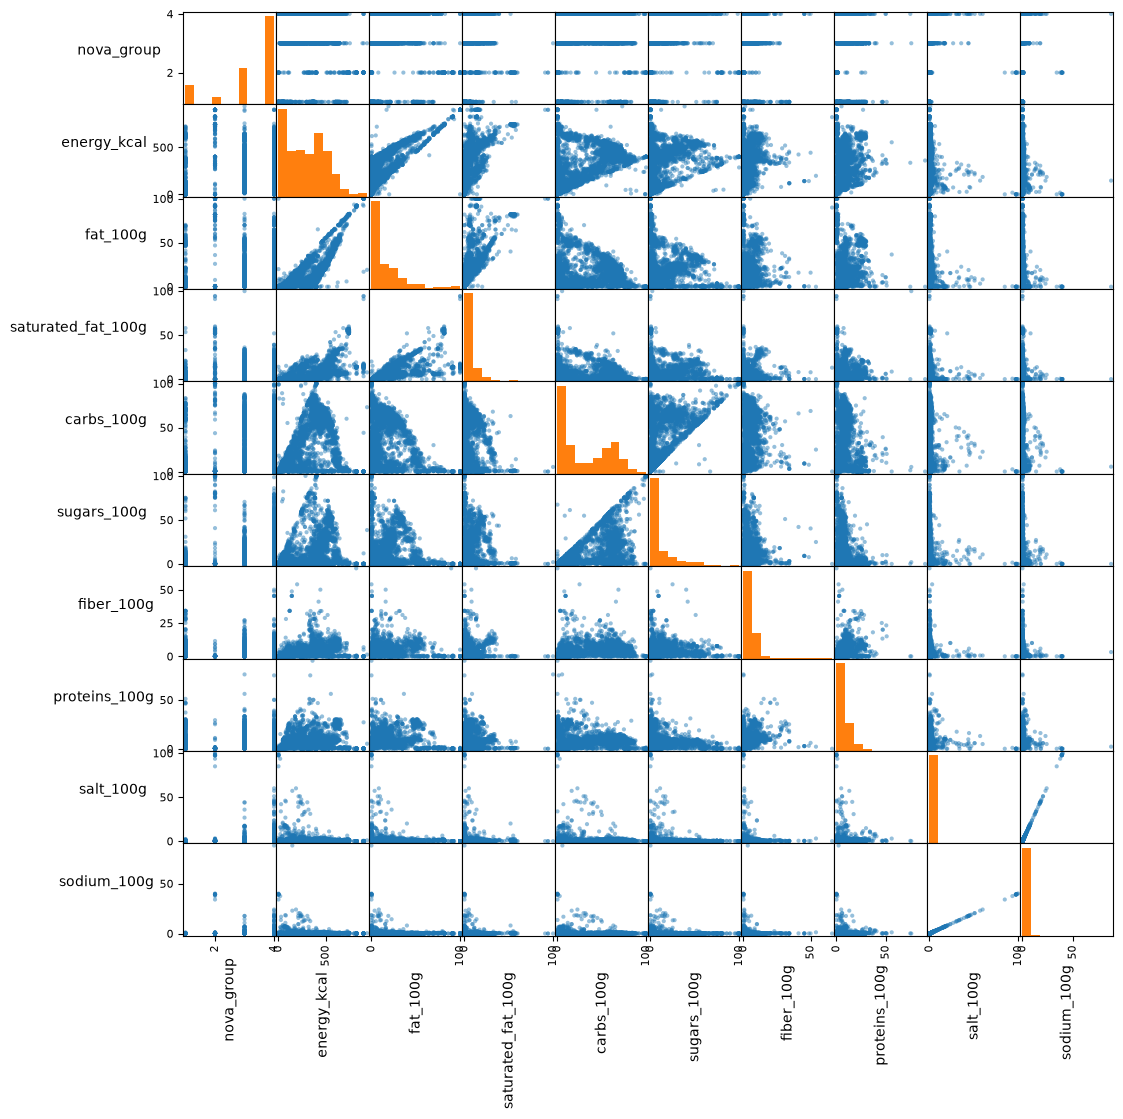

In [92]:
import matplotlib.pyplot as plt

dataset_limpio = revision_sin_invalidos.copy()

numeric_cols = dataset_limpio.select_dtypes(include=['number'])

# Crear el scatter matrix
axs = pd.plotting.scatter_matrix(numeric_cols, figsize=(12, 12), alpha=0.47, hist_kwds={'color':'#ff7f0e'})
# la mostramos por pantalla
# acomodamos la orientación del contenido de los ejes
for i in range(len(numeric_cols.columns)):
  for j in range(len(numeric_cols.columns)):
    ax=axs[i,j]
    ax.xaxis.label.set_rotation(90)
    ax.yaxis.label.set_rotation(0)
    ax.yaxis.label.set_ha('right')
plt.show()

5.2 - La sal y el sodio son variables dependientes, calculables una a partir de la otra. Por lo que en este caso eliminaremos el sodio.

In [93]:
dataset_limpio = dataset_limpio.drop(
    columns=["sodium_100g"]
)

La mayoría de relaciones que podemos observar son relaciones que conocemos con respecto a los macronutrientes. Por ejemplo, que la grasa proporciona mayor cantidad de calorías, o que los azucares son carbohidratos simples, por lo que son dependientes en cantidad cada 100g.

In [94]:
nutrientes = [
    "energy_kcal", "fat_100g", "saturated_fat_100g",
    "carbs_100g", "sugars_100g", "fiber_100g",
    "proteins_100g", "salt_100g"
]

datos = dataset_limpio[nutrientes]

resumen = datos.describe().T

resumen["nulos_%"] = datos.isna().mean() * 100
resumen["ceros_%_observados"] = (
    datos.eq(0).sum() / datos.notna().sum() * 100
)

display(resumen.round(2))

,count,mean,std,min,25%,50%,75%,max,nulos_%,ceros_%_observados
energy_kcal,4574.0,299.01,208.02,0.0,98.00,291.50,455.75,937.0,5.73,2.27
fat_100g,4585.0,15.76,20.31,0.0,1.50,7.50,23.00,100.0,5.50,9.29
saturated_fat_100g,4513.0,5.38,8.98,0.0,0.30,1.50,6.80,100.0,6.99,13.16
carbs_100g,4566.0,30.63,27.66,0.0,4.80,19.35,58.00,100.0,5.89,6.59
sugars_100g,4521.0,12.04,17.62,0.0,1.00,4.21,15.40,100.0,6.82,9.98
fiber_100g,3435.0,4.28,5.16,0.0,0.50,3.00,6.53,66.0,29.20,19.10
proteins_100g,4581.0,7.24,7.07,0.0,1.80,6.30,9.67,90.0,5.59,9.50
salt_100g,4546.0,1.24,6.00,0.0,0.03,0.31,0.98,100.0,6.31,11.28


Tenemos una gran cantidad de nulos y de ceros en la fibra cada 100g, podría significar presencia alta de alimentos de origen animal o ultraprocesados. El resto de variables tiene un porcentaje de nulos entre el 5 y el 7%, mientras que los ceros observados pueden ser válidos.

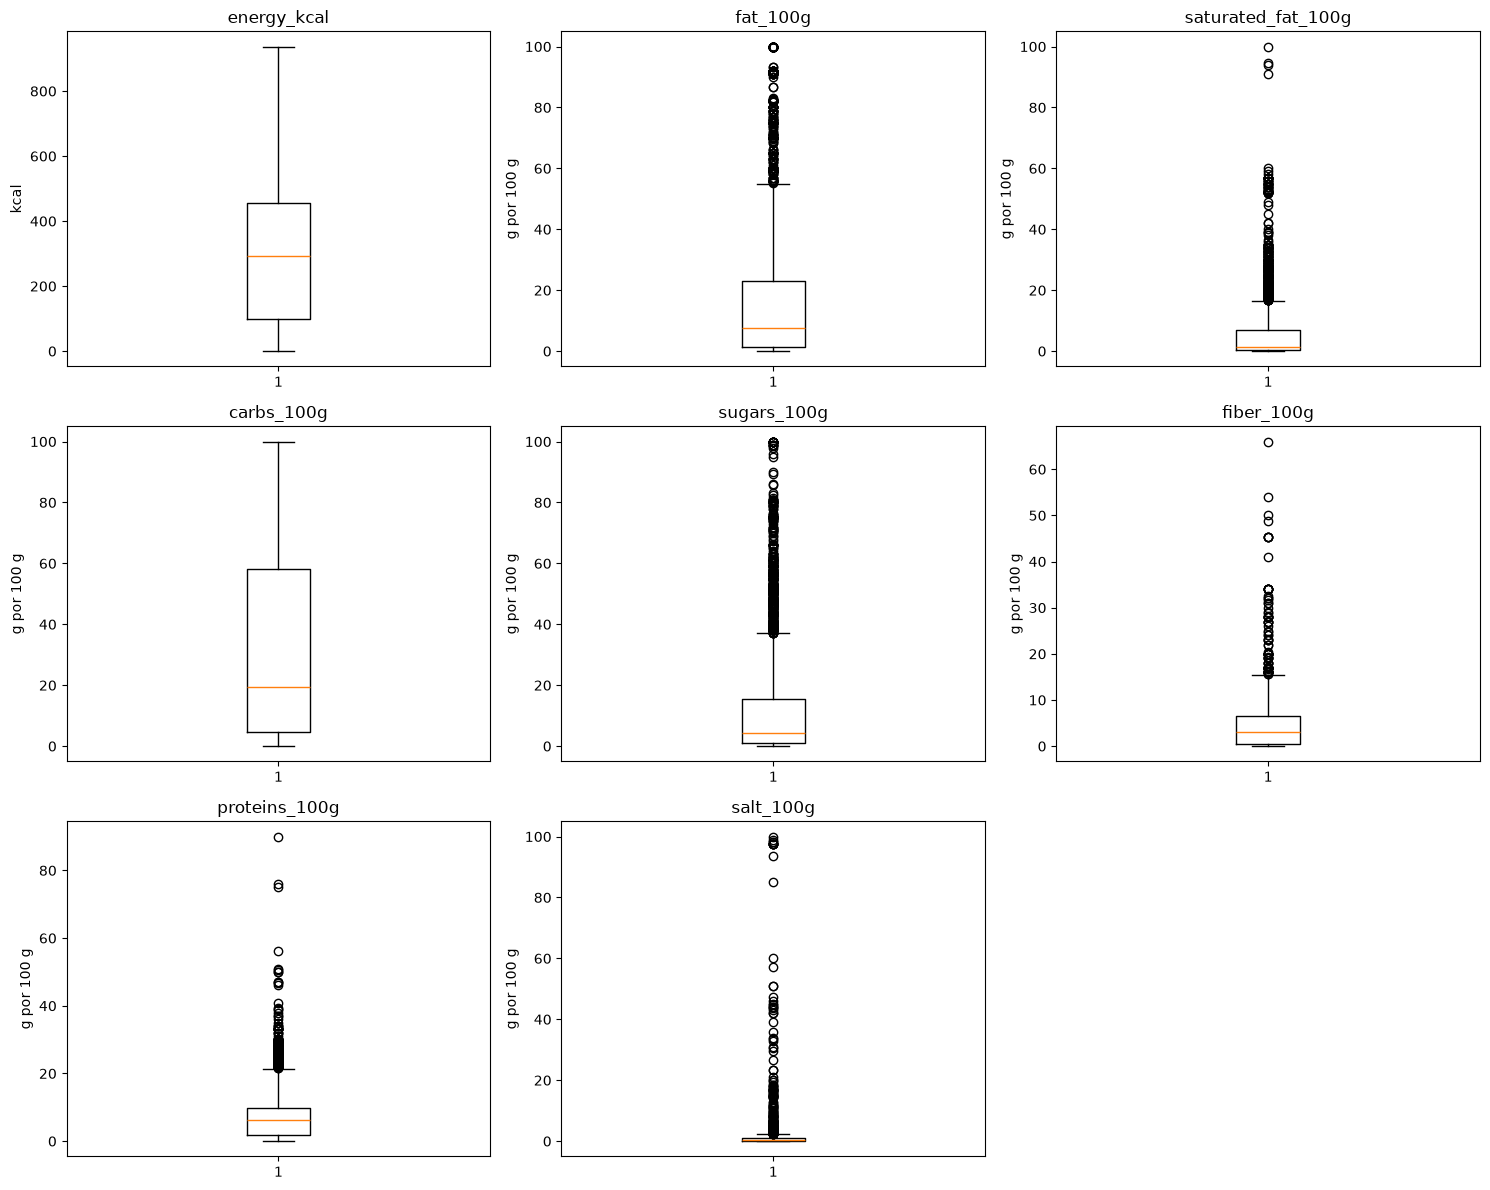

In [95]:
fig, ejes = plt.subplots(3, 3, figsize=(15, 12))

for eje, columna in zip(ejes.flat, nutrientes):
    valores = datos[columna].dropna()

    eje.boxplot(valores)
    eje.set_title(columna)
    eje.set_ylabel(
        "kcal" if columna == "energy_kcal" else "g por 100 g"
    )

for eje in list(ejes.flat)[len(nutrientes):]:
    eje.set_visible(False)

plt.tight_layout()
plt.show()

5.3 - Algunos gráficos están demasiado comprimidos, procederemos a quedarnos solamente con el 99% de los valores al graficar.

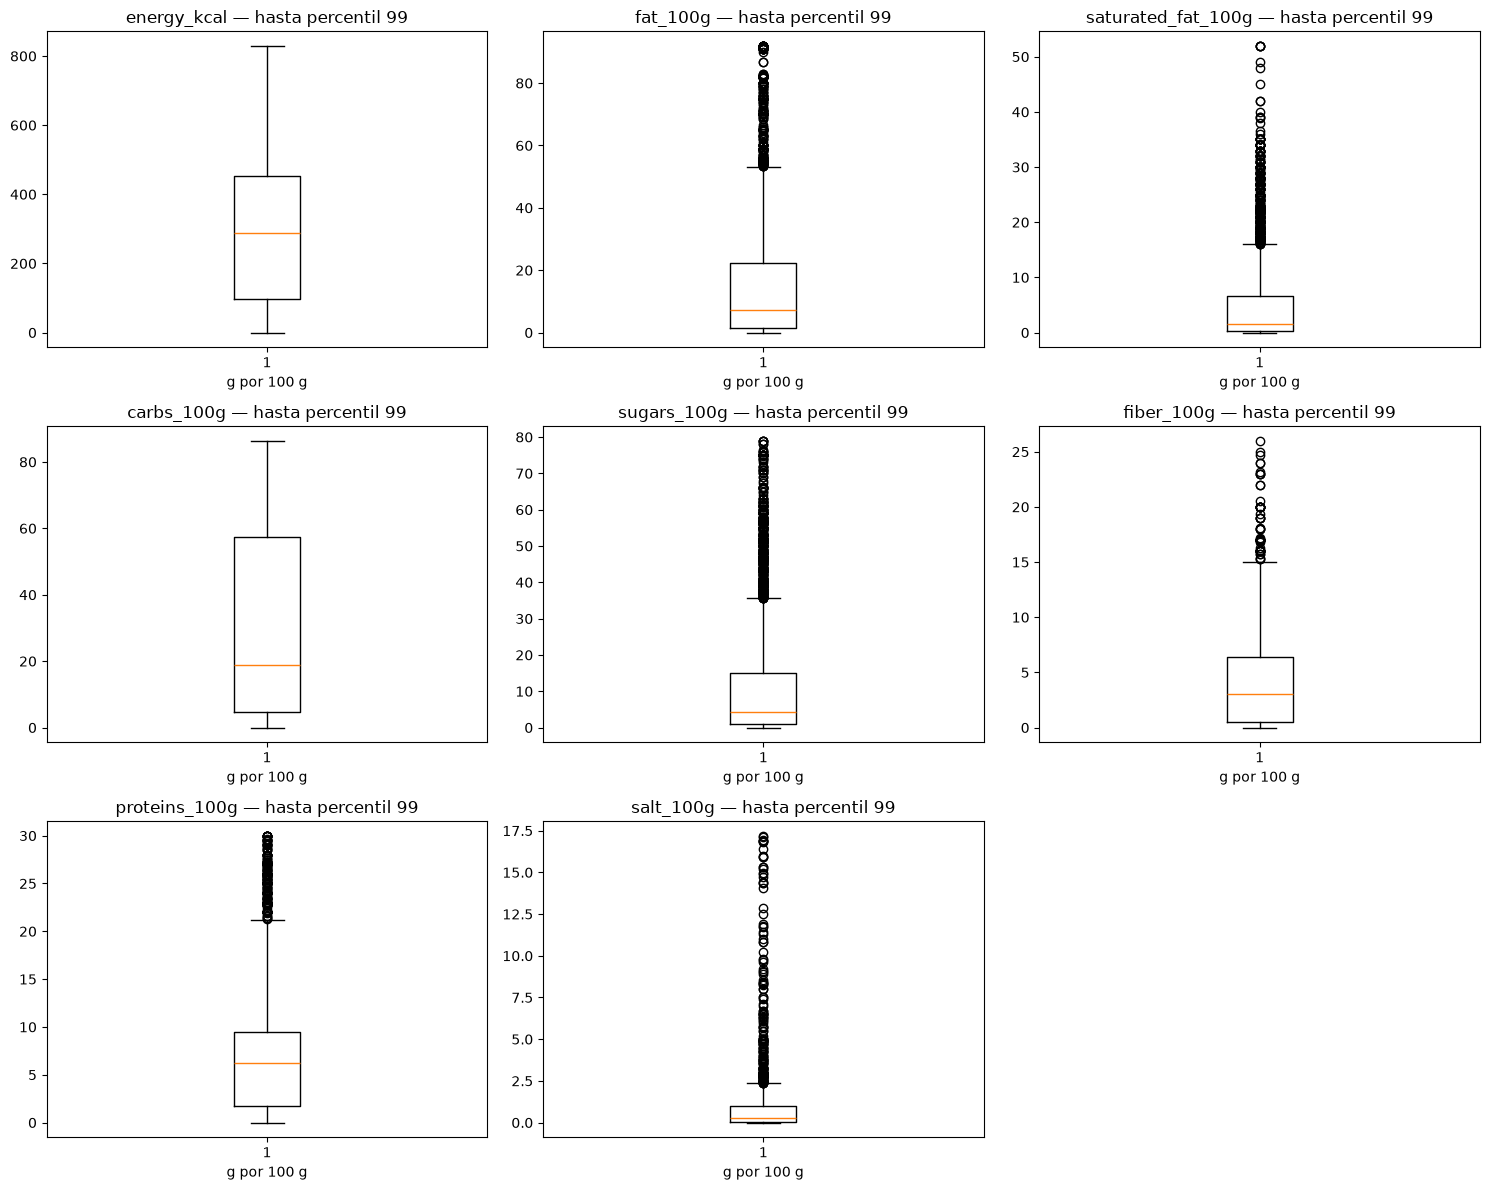

In [96]:
import matplotlib.pyplot as plt
import math

cantidad_filas = math.ceil(len(nutrientes) / 3)

fig, ejes = plt.subplots(
    cantidad_filas, 3,
    figsize=(15, 4 * cantidad_filas),
    squeeze=False
)

for eje, columna in zip(ejes.flat, nutrientes):
    valores = dataset_limpio[columna].dropna()

    limite_superior = valores.quantile(0.99)
    valores_visibles = valores[valores <= limite_superior]

    eje.boxplot(valores_visibles)
    eje.set_title(f"{columna} — hasta percentil 99")
    eje.set_xlabel("g por 100 g")


for eje in list(ejes.flat)[len(nutrientes):]:
    eje.set_visible(False)

plt.tight_layout()
plt.show()

5.4 - Al graficar las variables en boxplots, no parecen tener ninguna distribución conocida o aproximarse a la normal. Existe una gran cantidad de outliers, aunque más razonables que los vistos en el anterior gráfico, donde algunos valores podrían llegar a considerarse imposibles, habría que ver el contexto y de qué producto se trata antes de eliminarlos.

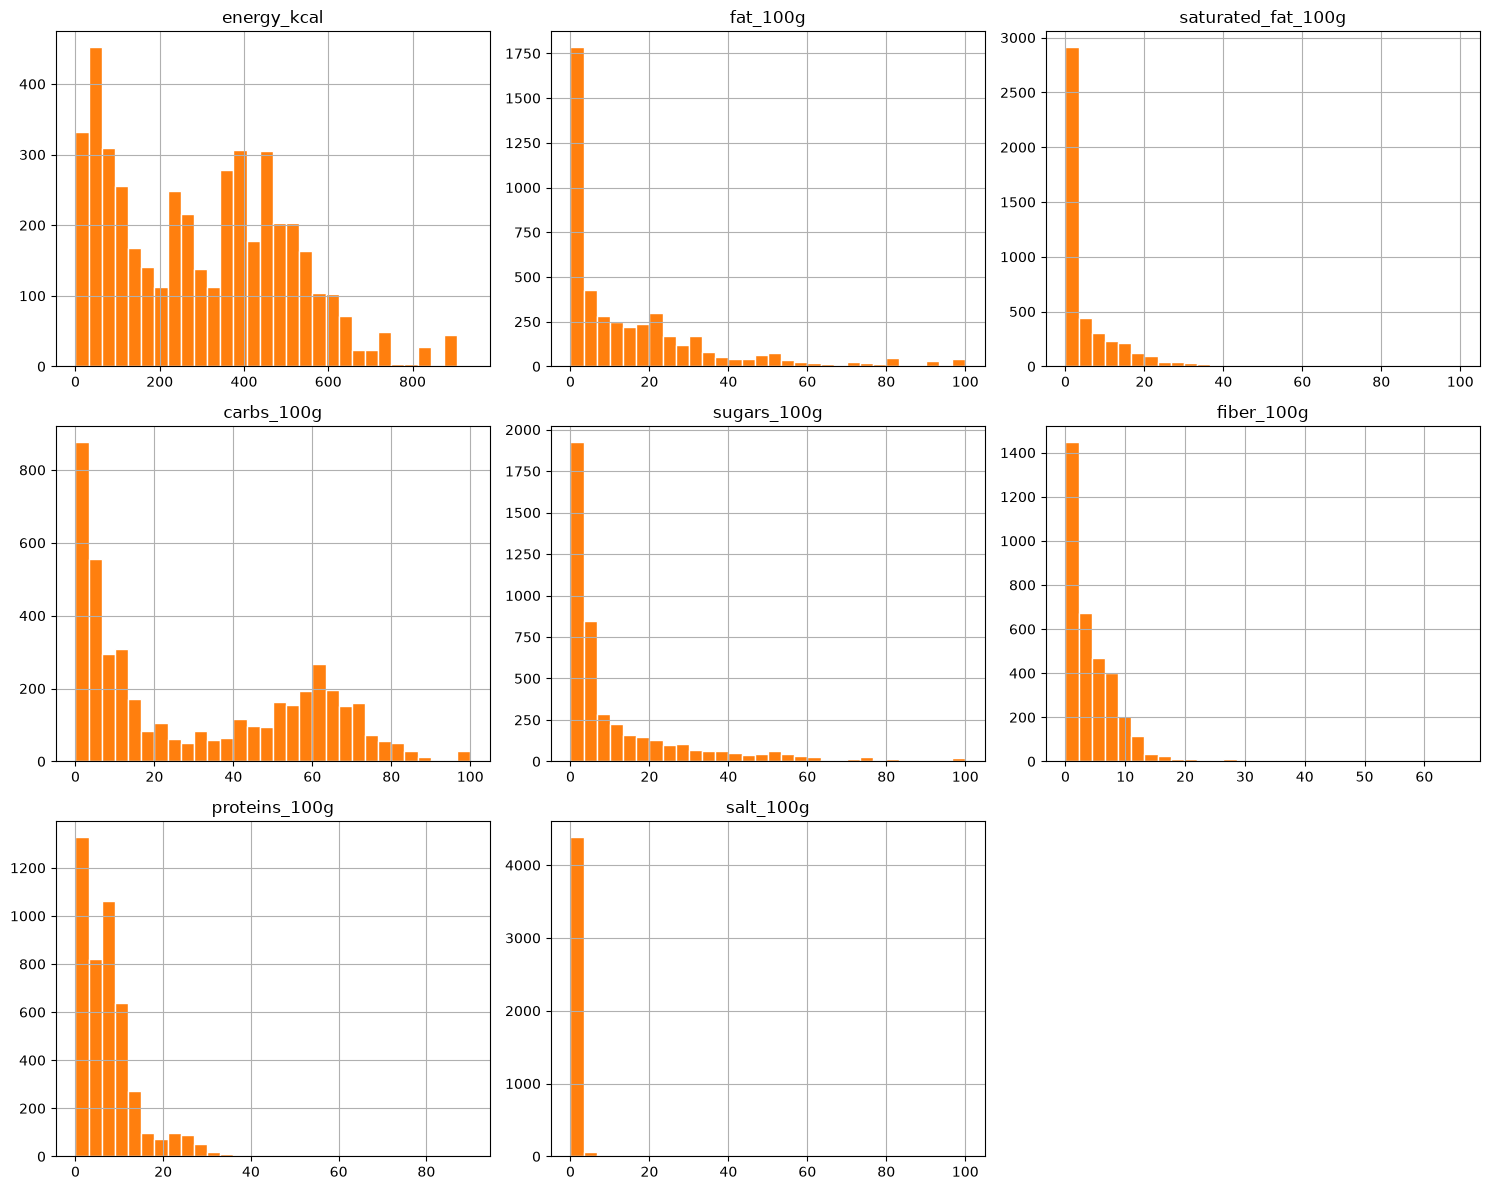

In [97]:
datos.hist(
    bins=30,
    figsize=(15, 12),
    color="#ff7f0e",
    edgecolor="white"
)

plt.tight_layout()
plt.show()

Predominan los valores bajos en todas las variables observadas, sin embargo, la primera barra incluye ceros y valores positivos pequeños. La cantidad de ceros en cada variable es alta, como apreciamos anteriormente. Todas tienen una asimetría hacia derecha.

## Sección 6 - Normalizando categorias

In [98]:
etiquetas_categorias = (
    dataset_limpio["categories"]
    .dropna()
    .str.split(",")
    .explode()
    .str.strip()
    .str.casefold()
)

frecuencias = etiquetas_categorias[
    etiquetas_categorias.ne("")
].value_counts()

display(frecuencias.to_frame("cantidad"))

,cantidad
categories,
en:plant-based-foods-and-beverages,2069
en:plant-based-foods,1754
en:snacks,1029
en:dairies,740
en:sweet-snacks,727
...,...
en:edulcorants-sucres-sucres-en-poudre,1
en:dumplings,1
en:korean-dumplings,1


In [99]:
# Descargar
categorias_para_clasificar = (
    frecuencias
    .rename_axis("categoria_original")
    .reset_index(name="cantidad")
)

categorias_para_clasificar.to_excel(
    "categorias_para_clasificar.xlsx",
    index=False
)

# files.download("categorias_para_clasificar.xlsx")

6.1 - Utilizamos Inteligencia Artificial para realizar el agrupamiento de categorías.

In [100]:
# Cada grupo contiene sus etiquetas originales.

etiquetas_por_grupo = {

    "Lácteos": """
        en:dairies
        en:fermented-milk-products
        en:milks
        en:milks-liquid-and-powder
        en:creams
        en:homogenized-milks
        en:uht-creams
        fr:creme-fromagere
        en:compound-dairy-creams
        en:whipped-creams
        en:evaporated-milks
        en:semi-skimmed-milks
        en:creme-cuisson
        ar:ياغورت
        fr:yaourt-veloute-pistache
        en:dairy-variety-packs
        fr:cremes-legeres
        en:condensed-milks
        fr:cremes-fraiches
        fr:cremes-allegees-en-matiere-grasse
        en:evaporated-milks-without-sugar
        en:uht-compound-dairy-creams-with-4-to-8-fat
        en:evaporated-milks-with-sugar
        en:laits
        en:laits-fluide-et-poudre
        en:laits-uht
    """.split(),

    "Bebidas lácteas": """
        en:dairy-drinks
        fr:yaourt-a-boire-aux-fruits
    """.split(),

    "Bebidas sin alcohol": """
        en:beverages
        en:beverages-and-beverages-preparations
        en:waters
        en:carbonated-drinks
        en:plant-based-beverages
        en:beverage-preparations
        en:spring-waters
        en:artificially-sweetened-beverages
        en:energy-drinks
        en:instant-beverages
        en:sodas
        en:tea-based-beverages
        en:non-alcoholic-beverages
        en:juice
        en:sweetened-beverages
        en:boissons
        en:boissons-aux-fruits
        en:iced-teas
        en:table-waters
        en:مشروب
        ar:soft-drinks
        ar:boisson-soda
        fr:boisson-soda
        en:energy-drink-with-sugar
        en:hot-beverages
        en:herbal-teas
        en:coffees
        nl:sportdrank
    """.split(),

    "Bebidas alcohólicas": """
        en:alcoholic-beverages
        en:beers
    """.split(),

    "Salsas y condimentos": """
        en:condiments
        en:sauces
        en:tomato-sauces
        en:mustards
        en:mayonnaises
        en:meal-sauces
        en:soy-sauces
        en:vinegars
        en:pestos
        en:pasta-sauces
        en:hot-sauces
        en:salad-dressings
        en:balsamic-vinegars
        en:cider-vinegars
        en:barbecue-sauces
        en:salted-spreads
        en:yeast-extract-spreads
        en:worcestershire-sauces
        en:salts
        en:sea-salts
        en:french-salts
        en:algerian-style-sauces
        fr:sels-fins
        en:wine-vinegars
        en:brown-sauces
        en:meat-based-sauces
        en:curry-sauces
        en:table-salts
        en:vegetarian-sauces
        en:indian-style-sauces
        en:oyster-sauces
        en:white-vinegars
        en:vanilla-sugars
        en:vanillin-sugars
        en:pizza-sauces
        en:american-style-sauces
        fr:sauces-andalouses
        en:malt-vinegars
        en:flavors
        en:tacos-sauce
        en:harissa-sauces
        en:cooking-sauces
        en:burger-sauces
        en:herbs-and-spices
        fr:sauce-biggy
        en:tzatzikis
        en:nuoc-mam-sauce
        en:tartare-sauces
    """.split(),

    "Grasas y aceites": """
        en:fats
        fr:huile-de-table
        en:animal-fats
        en:oil
        en:spreadable-fats
        en:huile-de-table
    """.split(),

    "Azúcares y endulzantes": """
        en:sweeteners
        en:sugars
        en:syrups
        en:simple-syrups
        en:brown-sugars
        en:cane-sugar
        en:sugar-substitutes
        en:flavoured-syrups
        en:granulated-sugars
        en:caster-sugars
        en:edulcorants-sucres-sucres-en-poudre
        en:powdered-sugars
        en:beet-sugars
        en:coconut-sugar
    """.split(),

    "Cacao, chocolates y untables dulces": """
        en:cocoa-and-its-products
        en:sweet-spreads
        en:cocoa-and-chocolate-powders
        en:cocoa-powders
        fr:chocolat-a-tartiner
        en:cacao-nibs
    """.split(),

    "Galletas, panadería y pastelería": """
        en:biscuits-and-cakes
        en:sweet-pastries-and-pies
        en:crepes-and-galettes
        en:sourdough-bread
        fr:crumpets
        en:crumpets
        en:midi-flatbread
        en:galletas
        en:pastry-snack
        en:crumpet
        fr:tortillas-avoine-et-ble
        fr:crepes-de-froment
        fr:gateau-fourre-chocolat
        en:crepes
        en:pancakes
        en:crepes-et-galettes
        en:seeded-bread
    """.split(),

    "Cereales, pastas y derivados": """
        en:cereals-and-potatoes
        en:pastas
        fr:cereales-preparees
        en:cereales-et-derives
        fr:cereales-completes
        fr:cruesli
        en:flakes
    """.split(),

    "Legumbres y alternativas vegetales": """
        en:legumes-and-their-products
        en:meat-alternatives
        en:meat-analogues
        en:vegetarian-patties
        en:vegetarian-sausages
        en:vegetarian-balls
        en:prepared-meat-cuts-substitutes
        en:cereals-and-vegetables-patties
        fr:tranches-vegetales
        en:falafels
        en:meat-analogues-from-soy-or-wheat-proteins
        en:tofu-patties
        es:hamburguesas-vegetales-espinacas-y-zanahoria
    """.split(),

    "Sustitutos de lácteos": """
        en:dairy-substitutes
        en:plant-based-creams
        en:plantaardige-kaas-voor-maaltijden
        en:plantaardige-kaas
    """.split(),

    "Frutas y verduras": """
        en:fruits-and-vegetables-based-foods
        en:prepared-vegetables
        en:pickles
        en:vegetables-prepared-processed-shelf-stable
    """.split(),

    "Frutos secos y semillas": """
        en:nuts-and-their-products
        en:seeds
    """.split(),

    "Carnes y derivados": """
        en:meats-and-their-products
        en:prepared-meats
        en:meats
        en:pork-and-its-products
        en:meat-preparations
        fr:charcuteries-cuites
        en:chicken-and-its-products
        en:hams
        en:sausages
        en:poultries
        en:beef-and-its-products
    """.split(),

    "Pescados y mariscos": """
        en:seafood
        en:fishes-and-their-products
        en:fishes
        en:fish-preparations
    """.split(),

    "Huevos": """
        en:eggs
        en:chicken-eggs
    """.split(),

    "Platos preparados": """
        en:meals
        en:meals-with-meat
        en:pizzas-pies-and-quiches
        en:meals-with-fish
        en:pasta-dishes
        en:savory-semolina-dishes
        en:prepared-salads
        en:pizzas
        en:rice-dishes
        en:microwave-meals
        en:prepared-rices
        en:tabbouleh
        en:potato-dishes
        en:dumplings
        en:stuffing
        en:cod-brandade
        en:poultry-sandwiches
        en:spanish-omelettes
        en:prepared-couscous
        fr:refeicoes
        fr:refeicoes-para-micro-ondas
        en:gratins
        en:quiches
        en:beef-dishes
        en:chicken-tabbouleh
        en:stuffed-vine-leaves
        en:sandwiches
        en:korean-dumplings
    """.split(),

    "Sopas y caldos": """
        en:broths
        en:soups
        en:reheatable-soups
        en:chicken-soups
        en:beef-broth
        en:bouillon-pots
        en:chicken-stock
    """.split(),

    "Snacks salados": """
        en:salty-snacks
        en:popcorn
        en:frozen-fried-potatoes
        en:chips-and-fries
        en:snacks-sales
        en:corn-snack
    """.split(),

    "Snacks dulces y golosinas": """
        en:sweet-snacks
        en:bars
        en:confectioneries
        fr:barre-de-cereales-a-la-creme-de-lait
    """.split(),

    "Postres": """
        en:desserts
        en:dairy-desserts
        en:frozen-desserts
        en:puddings
        en:dessert-mixes
        fr:preparations-pour-flans
        en:chocolate-desserts
        en:sweet-mousses
        en:rice-puddings
        fr:creme-dessert-riche-en-proteines
    """.split(),

    "Alimentación infantil": """
        en:baby-foods
        en:baby-milks
        en:growth-milks
        fr:cerelac-pour-enfants
        en:snacks-and-desserts-for-babies
        en:biscuits-for-babies
    """.split(),

    "Suplementos y nutrición especializada": """
        en:dietary-supplements
        en:bodybuilding-supplements
        en:vitamins
        en:meal-replacements
        en:complements-alimentaires
        fr:supplement-de-proteines
        en:fitness-nutrition
        fr:minereaux
        en:protein-bars
        en:supplements
        ar:magnesio
        en:creatine
    """.split(),

    "Ingredientes y ayudas de cocina": """
        en:food-additives
        en:cooking-helpers
        en:yeast
        en:baker-s-yeast
        en:baking-powder-or-raising-agent
        en:pastry-helpers
        en:baking-powder
        fr:poudres-a-lever
        en:baking-mixes
        en:sourdough
        en:dried-yeast
        en:nutritional-yeast
    """.split(),

    "No alimentario / medicamentos": """
        en:non-food-products
        en:open-beauty-facts
        en:cigarettes
        en:medicine
        fr:creme-main
        en:health-beauty
        fr:shampoing
        ar:مستحقات-التجميل
        en:shampoo
        en:wipes
        fr:fumer
        fr:creme-hydratante
        fr:antibiotique
        en:adhesives
        en:adhesives-and-sealants
        en:glues
    """.split(),
}

etiquetas_generales = """
    en:plant-based-foods-and-beverages
    en:plant-based-foods
    en:snacks
    en:fermented-foods
    en:breakfasts
    en:spreads
    en:appetizers
    en:canned-foods
    en:frozen-foods
    en:dried-products
    en:dried-products-to-be-rehydrated
    en:fresh-foods
    en:groceries
    en:vegan-products
    en:specific-products
    en:breaded-products
    en:mountain-products
    en:aliments-et-boissons-a-base-de-vegetaux
    en:farming-products
    en:aliments-d-origine-vegetale
    en:refrigerated-foods
    fr:ingredients
    en:healthy
    en:easter-food
    en:festive-foods
    en:aperitif
    en:variety-packs
    en:other
    en:vegetarisch
    en:vegetarian-snacks
    en:alimentos-de-origen-vegetal
    ar:المكونات
    en:vegan
""".split()

etiquetas_por_revisar = """
    en:type
    en:mensouria
    en:هبا٨د
    fr:sidi-ali
    fr:coca-cola
    ar:bad
    fr:cachet-effervescent
    en:pots
    fr:sprite
    fr:ouile
    fr:maroc
    ar:بلار
    fr:yz
    fr:novobac
    ar:enfants
    fr:240
    en:heie
    ar:fzg
    fr:bien
    el:γλυκό
    en:a
    fr:danoune
    fr:king
    fr:الكف
    en:clea
""".split()

In [101]:
mapa_categorias = {}

for grupo, etiquetas in etiquetas_por_grupo.items():
    for etiqueta in etiquetas:
        if etiqueta in mapa_categorias:
            raise ValueError(f"Etiqueta asignada dos veces: {etiqueta}")

        mapa_categorias[etiqueta] = grupo

for etiqueta in etiquetas_generales:
    mapa_categorias[etiqueta] = None

for etiqueta in etiquetas_por_revisar:
    mapa_categorias[etiqueta] = "Revisar"

In [102]:
def agrupar_categorias(texto):
    if pd.isna(texto) or not texto.strip():
        return []

    grupos = set()

    for etiqueta in texto.split(","):
        etiqueta = etiqueta.strip().casefold()
        grupo = mapa_categorias.get(etiqueta)

        if grupo is not None and grupo != "Revisar":
            grupos.add(grupo)

    return sorted(grupos)


dataset_limpio["categorias_agrupadas"] = (
    dataset_limpio["categories"].apply(agrupar_categorias)
)

In [103]:
pendientes = frecuencias[ frecuencias.index.isin(mapa_categorias) == False
]

display(pendientes.to_frame("cantidad"))

,cantidad
categories,


Existen productos que no tienen categorías de alimentos, revisamos cuales son:

In [104]:
def tiene_etiqueta_no_alimentaria(texto):
    if pd.isna(texto):
        return False

    for etiqueta in texto.split(","):
        grupo = mapa_categorias.get(etiqueta.strip().casefold())

        if grupo == "No alimentario / medicamentos":
            return True

    return False


revisar_no_alimentarios = dataset_limpio["categories"].apply(tiene_etiqueta_no_alimentaria)

display(dataset_limpio.loc[revisar_no_alimentarios, ["product_name", "brands", "categories"]])

,product_name,brands,categories
831,NaN,NaN,fr:shampoing
927,Magnesium,Mivolis,"en:dietary-supplements, en:fitness-nutrition, ..."
1050,NaN,NaN,fr:creme-main
1058,rinomicine,Rinomicine,"en:medicine, en:non-food-products, en:open-bea..."
1159,NaN,NaN,"en:non-food-products, en:cigarettes"
1905,NaN,Beiersdorf,ar:مستحقات-التجميل
2979,NaN,NaN,en:shampoo
3159,Doliprane,NaN,"en:non-food-products, en:open-beauty-facts"
3220,NaN,NaN,fr:creme-hydratante
3432,NaN,NaN,en:wipes


6.2 - Excepto el magnesio que se considera suplemento deportivo, el resto no son adecuados para el análisis. Los eliminamos.

In [105]:
eliminar = ( revisar_no_alimentarios & (dataset_limpio.index != 927) )

print("Productos eliminados:", eliminar.sum())

dataset_limpio = dataset_limpio.loc[eliminar == False].copy()

Productos eliminados: 12


In [106]:
dataset_limpio.head()

,product_name,brands,categories,ingredients,nutriscore_grade,nova_group,ecoscore_grade,allergens,energy_kcal,fat_100g,...,salt_100g,contains_gluten,contains_dairy,contains_nuts,contains_soy,contains_eggs,contains_fish,product_name_normalizado,brands_normalizado,categorias_agrupadas
0,Sidi Ali,سيدي علي,"en:beverages-and-beverages-preparations, en:be...",OBD1 999 999 1112606 266963207 mb,A,NaN,NOT-APPLICABLE,NaN,0.0,0.0,...,0.000000,False,False,False,False,False,False,sidi ali,سيدي علي,[Bebidas sin alcohol]
1,Perly,Perly,"en:dairies, en:fermented-foods, en:fermented-m...","milk cream, cream, sugar, banana, bacteria",UNKNOWN,3.0,B,"en:banana, en:milk",97.0,3.0,...,NaN,False,True,False,False,False,False,perly,perly,[Lácteos]
2,Sidi Ali,Sidi Ali,"en:beverages-and-beverages-preparations, en:be...","Sodium, Calcium, Magnésium, Potassium, Bicarbo...",A,1.0,NOT-APPLICABLE,NaN,NaN,NaN,...,0.065000,False,False,False,False,False,False,sidi ali,sidi ali,[Bebidas sin alcohol]
3,Eau minérale naturelle,sidi ali,"en:beverages-and-beverages-preparations, en:be...",100% mineral water,A,1.0,NOT-APPLICABLE,NaN,NaN,NaN,...,0.065000,False,False,False,False,False,False,eau minérale naturelle,sidi ali,[Bebidas sin alcohol]
4,اكوافينا,AQUAFINA,"en:beverages-and-beverages-preparations, en:be...",ouverture et avant le : Voir bouteille. après ...,A,NaN,NOT-APPLICABLE,NaN,0.0,0.0,...,0.000508,False,False,False,False,False,False,اكوافينا,aquafina,[Bebidas sin alcohol]


Existen registros que quedaron con más de una categoría, establecemos una lista de prioridades para luego solo dejarlos con una categoría.

In [107]:
prioridad_categorias = [
    "No alimentario / medicamentos",
    "Alimentación infantil",
    "Suplementos y nutrición especializada",
    "Bebidas alcohólicas",
    "Bebidas lácteas",
    "Bebidas sin alcohol",
    "Sopas y caldos",
    "Platos preparados",
    "Postres",
    "Galletas, panadería y pastelería",
    "Cacao, chocolates y untables dulces",
    "Snacks salados",
    "Snacks dulces y golosinas",
    "Salsas y condimentos",
    "Grasas y aceites",
    "Azúcares y endulzantes",
    "Sustitutos de lácteos",
    "Legumbres y alternativas vegetales",
    "Carnes y derivados",
    "Pescados y mariscos",
    "Huevos",
    "Lácteos",
    "Frutos secos y semillas",
    "Frutas y verduras",
    "Cereales, pastas y derivados",
    "Ingredientes y ayudas de cocina",
]


def asignar_categoria_principal(grupos):
    if not isinstance(grupos, list) or len(grupos) == 0:
        return "Sin clasificar"

    for categoria in prioridad_categorias:
        if categoria in grupos:
            return categoria

    return "Revisar"


dataset_limpio["categoria_principal"] = (
    dataset_limpio["categorias_agrupadas"]
    .apply(asignar_categoria_principal)
)

display(
    dataset_limpio["categoria_principal"].value_counts()
)

categoria_principal
Bebidas sin alcohol                      699
Sin clasificar                           633
Lácteos                                  567
Cereales, pastas y derivados             505
Galletas, panadería y pastelería         363
Salsas y condimentos                     342
Cacao, chocolates y untables dulces      338
Frutas y verduras                        216
Grasas y aceites                         208
Legumbres y alternativas vegetales       207
Snacks salados                           134
Snacks dulces y golosinas                108
Postres                                   93
Pescados y mariscos                       91
Platos preparados                         84
Carnes y derivados                        59
Azúcares y endulzantes                    45
Frutos secos y semillas                   36
Sustitutos de lácteos                     31
Sopas y caldos                            24
Suplementos y nutrición especializada     19
Ingredientes y ayudas de cocina    

Existen una gran cantidad de elementos sin clasificar ya que no tenían categoría originalmente, o era demasiado genérica. Para graficar agruparemos nuevamente, ya que existen demasiadas categorías.

In [108]:
agrupaciones_graficos = {
    "Lácteos y alternativas": [
        "Lácteos",
        "Bebidas lácteas",
        "Sustitutos de lácteos"
    ],
    "Bebidas": [
        "Bebidas sin alcohol",
        "Bebidas alcohólicas"
    ],
    "Dulces, postres y pastelería": [
        "Postres",
        "Galletas, panadería y pastelería",
        "Cacao, chocolates y untables dulces",
        "Snacks dulces y golosinas"
    ],
    "Platos preparados y sopas": [
        "Platos preparados",
        "Sopas y caldos"
    ],
    "Carnes, pescados y huevos": [
        "Carnes y derivados",
        "Pescados y mariscos",
        "Huevos"
    ],
    "Vegetales, cereales y legumbres": [
        "Frutas y verduras",
        "Cereales, pastas y derivados",
        "Legumbres y alternativas vegetales",
        "Frutos secos y semillas"
    ],
    "Azúcares y endulzantes": [
        "Azúcares y endulzantes"
    ],
    "Salsas y condimentos": [
        "Salsas y condimentos"
    ],
    "Grasas y aceites": [
        "Grasas y aceites"
    ],
    "Snacks salados": [
        "Snacks salados"
    ],
    "Otros": [
        "Ingredientes y ayudas de cocina",
        "Alimentación infantil",
        "Suplementos y nutrición especializada"
    ]
}

mapa_graficos = {}

for grupo_amplio, categorias in agrupaciones_graficos.items():
    for categoria in categorias:
        mapa_graficos[categoria] = grupo_amplio

dataset_limpio["categoria_grafico"] = (
    dataset_limpio["categoria_principal"]
    .map(mapa_graficos)
    .fillna("Sin clasificar")
)

display(
    dataset_limpio["categoria_grafico"].value_counts()
)

categoria_grafico
Vegetales, cereales y legumbres    964
Dulces, postres y pastelería       902
Bebidas                            708
Sin clasificar                     634
Lácteos y alternativas             600
Salsas y condimentos               342
Grasas y aceites                   208
Carnes, pescados y huevos          153
Snacks salados                     134
Platos preparados y sopas          108
Azúcares y endulzantes              45
Otros                               42
Name: count, dtype: int64

In [109]:
excluir = ["Sin clasificar", "Otros"]

datos = dataset_limpio.loc[ dataset_limpio["categoria_grafico"].isin(excluir) == False ].copy()

In [110]:
def graficar_barras_agrupadas(datos, columna, niveles, nivel_orden, colores, titulo):
    datos_validos = datos.loc[datos[columna].isin(niveles)]

    cantidades = pd.crosstab(datos_validos["categoria_grafico"], datos_validos[columna]).reindex(columns=niveles, fill_value=0)

    porcentajes = cantidades.div(cantidades.sum(axis=1), axis=0) * 100

    porcentajes = porcentajes.sort_values(
        by=nivel_orden,
        ascending=True,
        kind="stable"
    )

    eje = porcentajes.plot.bar(
        stacked=False,
        figsize=(16, 7),
        color=colores,
        width=0.85
    )

    etiquetas = []

    for categoria in porcentajes.index:
        cantidad = cantidades.loc[categoria].sum()
        etiquetas.append(f"{categoria}\n(n={cantidad})")

    eje.set_xticklabels(etiquetas, rotation=45, ha="right")
    eje.set_xlabel("Categoría")
    eje.set_ylabel("Porcentaje dentro de cada categoría")
    eje.set_title(titulo)
    eje.legend(title=columna, bbox_to_anchor=(1.02, 1))
    eje.grid(axis="y", alpha=0.2)
    eje.set_axisbelow(True)

    plt.tight_layout()
    plt.show()

6.3 - Analizamos Eco-Score en relación a las categorías de los productos.

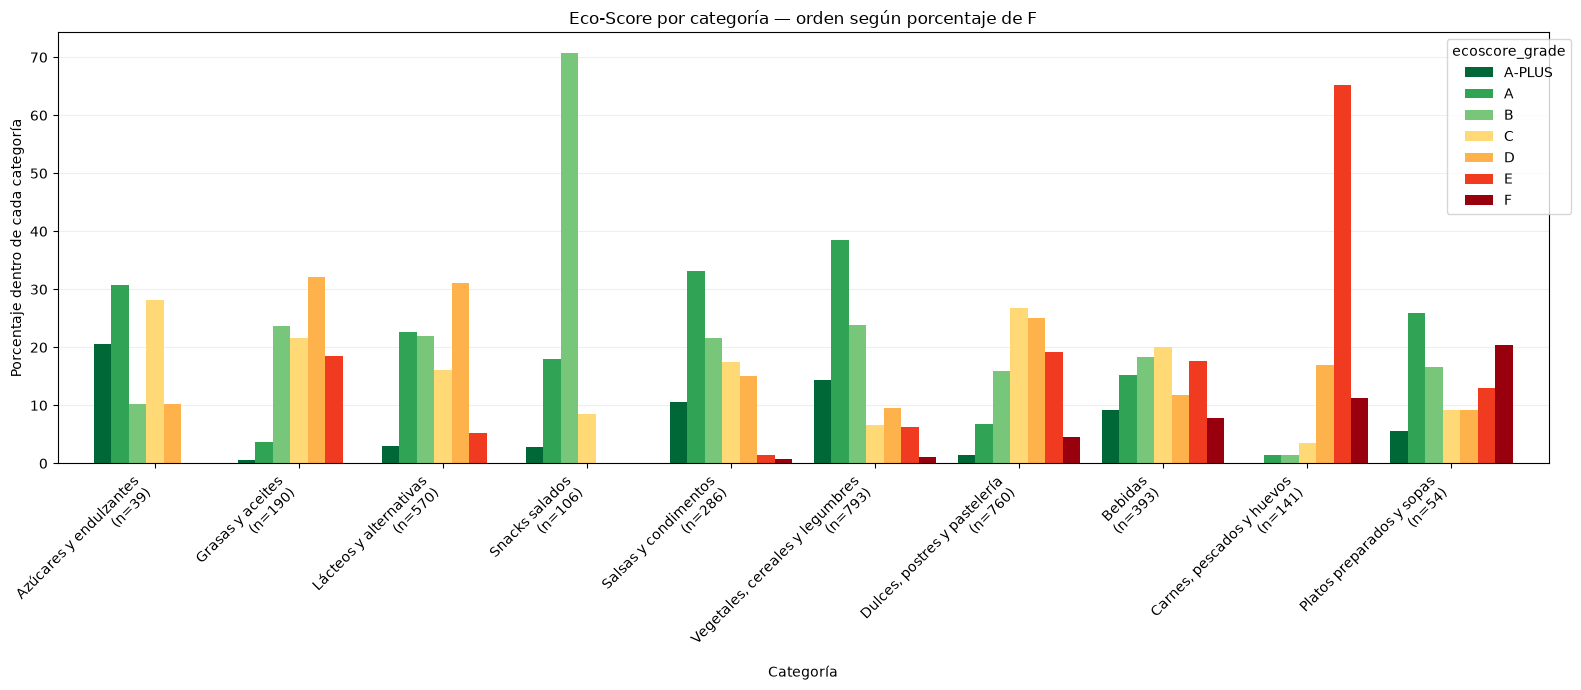

In [111]:
datos["ecoscore_grade"] = (
    datos["ecoscore_grade"]
    .astype("string")
    .str.strip()
    .str.upper()
)

graficar_barras_agrupadas(
    datos,
    columna="ecoscore_grade",
    niveles=["A-PLUS", "A", "B", "C", "D", "E", "F"],
    nivel_orden="F",
    colores=[
        "#006837", "#31a354", "#78c679",
        "#fed976", "#feb24c", "#f03b20", "#99000d"
    ],
    titulo="Eco-Score por categoría — orden según porcentaje de F"
)

6.4 - Analizamos NOVA en relación a las categorías de los productos.

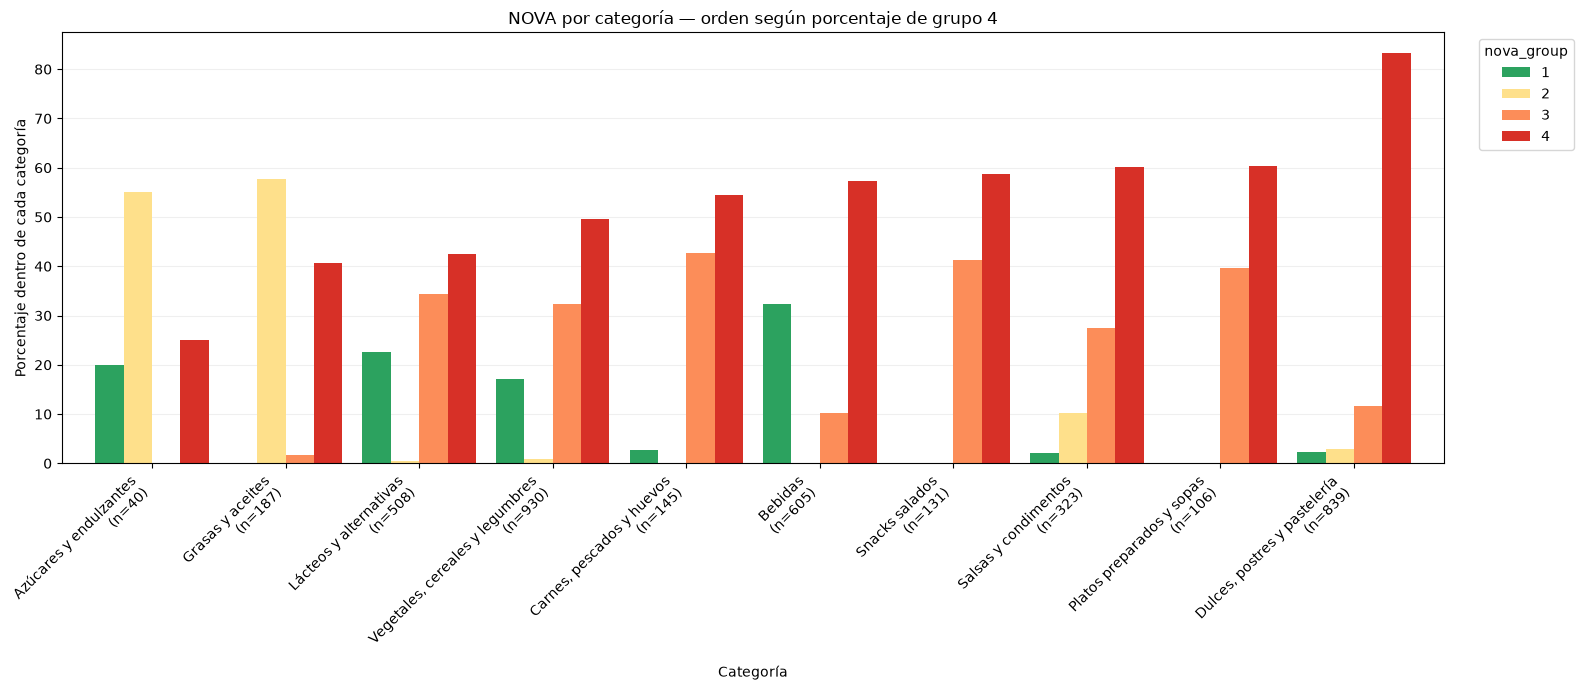

In [112]:
datos["nova_group"] = pd.to_numeric(datos["nova_group"], errors="coerce")

graficar_barras_agrupadas(
    datos,
    columna="nova_group",
    niveles=[1, 2, 3, 4],
    nivel_orden=4,
    colores=["#2ca25f", "#fee08b", "#fc8d59", "#d73027"],
    titulo="NOVA por categoría — orden según porcentaje de grupo 4"
)

## Sección 7 - Reducción de dimensionalidad

In [113]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

columnas_pca = [
    "energy_kcal",
    "fat_100g",
    "saturated_fat_100g",
    "carbs_100g",
    "sugars_100g",
    "fiber_100g",
    "proteins_100g",
    "salt_100g"
]

datos_pca = dataset_limpio[columnas_pca].copy().dropna()

scaler = StandardScaler()
datos_estandarizados = scaler.fit_transform(datos_pca)

# Calcular todos los componentes para evaluar la información conservada.
pca = PCA()
componentes = pca.fit_transform(datos_estandarizados)

nombres_componentes = []

for numero in range(1, componentes.shape[1] + 1):
    nombres_componentes.append(f"PC{numero}")

resultado_pca = pd.DataFrame(
    componentes,
    index=datos_pca.index,
    columns=nombres_componentes
)

display(resultado_pca.head())


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8
0,-2.398823,-0.853939,-0.552771,-0.587092,0.333334,-0.001590,-0.016683,-0.065114
4,-2.448061,-0.991966,-0.500107,-0.607991,0.356813,0.014168,-0.049773,-0.005839
6,-2.448099,-0.992007,-0.500116,-0.607631,0.356827,0.014169,-0.049779,-0.005839
7,-1.581513,-1.028780,0.117562,-0.480041,-0.380690,0.120602,-0.252540,-0.298702
9,-0.038960,-1.906484,-0.296534,-0.343334,-0.189040,0.386612,0.721648,-0.003132


In [114]:
varianza_explicada = pca.explained_variance_ratio_ * 100
varianza_acumulada = np.cumsum(varianza_explicada)

resumen_pca = pd.DataFrame({
    "componente": nombres_componentes,
    "varianza_explicada": varianza_explicada,
    "varianza_acumulada": varianza_acumulada
})

display(resumen_pca)

,componente,varianza_explicada,varianza_acumulada
0,PC1,32.531160,32.531160
1,PC2,20.478723,53.009883
2,PC3,17.099824,70.109707
3,PC4,12.182071,82.291778
4,PC5,7.717362,90.009140
5,PC6,5.853277,95.862417
6,PC7,4.006627,99.869044
7,PC8,0.130956,100.000000


Sección 7.1 - Análisis del peso de los nutrientes en los primeros 2 componentes

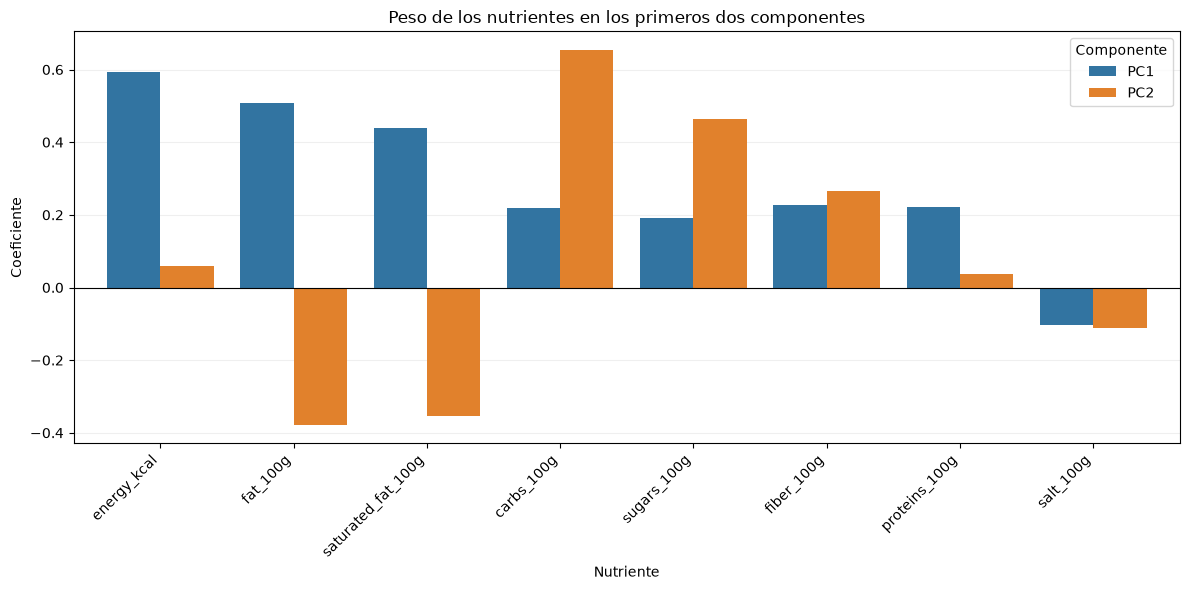

In [115]:
import pandas as pd
import matplotlib.pyplot as plt

pesos = pd.DataFrame(
    pca.components_[:2].T,
    index=columnas_pca,
    columns=["PC1", "PC2"]
)

eje = pesos.plot.bar(
    figsize=(12, 6),
    color=["#3274A1", "#E1812C"],
    width=0.8
)

eje.set_title("Peso de los nutrientes en los primeros dos componentes")
eje.set_xlabel("Nutriente")
eje.set_ylabel("Coeficiente")
eje.axhline(0, color="black", linewidth=0.8)
eje.grid(axis="y", alpha=0.2)
eje.set_axisbelow(True)

plt.xticks(rotation=45, ha="right")
plt.legend(title="Componente")
plt.tight_layout()
plt.show()

In [116]:
datos_coloreados = resultado_pca[["PC1", "PC2"]].copy()

datos_coloreados["nova_group"] = pd.to_numeric(
    dataset_limpio.loc[datos_coloreados.index, "nova_group"],
    errors="coerce"
)

datos_coloreados["ecoscore_grade"] = (
    dataset_limpio.loc[datos_coloreados.index, "ecoscore_grade"]
    .astype("string")
    .str.strip()
    .str.upper()
)

def graficar_pca_coloreado(columna, colores, titulo):
    fig, eje = plt.subplots(figsize=(12, 8))

    # Mostrar primero los productos sin clasificación válida.
    sin_clasificacion = (
        datos_coloreados[columna].isin(list(colores)) == False
    )

    puntos = datos_coloreados.loc[sin_clasificacion]

    if not puntos.empty:
        eje.scatter(
            puntos["PC1"],
            puntos["PC2"],
            color="lightgray",
            alpha=0.25,
            s=15,
            label="Sin clasificación válida"
        )

    for nivel, color in colores.items():
        puntos = datos_coloreados.loc[
            datos_coloreados[columna] == nivel
        ]

        if puntos.empty:
            continue

        eje.scatter(
            puntos["PC1"],
            puntos["PC2"],
            color=color,
            alpha=0.45,
            s=18,
            label=f"{nivel} (n={len(puntos)})"
        )

    escala_flechas = 5

    for posicion, variable in enumerate(columnas_pca):
        extremo_x = pca.components_[0, posicion] * escala_flechas
        extremo_y = pca.components_[1, posicion] * escala_flechas

        eje.annotate(
            "",
            xy=(extremo_x, extremo_y),
            xytext=(0, 0),
            arrowprops={
                "arrowstyle": "->",
                "color": "black",
                "lw": 1.5
            }
        )

        eje.text(
            extremo_x * 1.12,
            extremo_y * 1.12,
            variable,
            fontsize=9
        )

    eje.set_xlabel(
        f"PC1 ({varianza_explicada[0]:.1f}% de variabilidad)"
    )
    eje.set_ylabel(
        f"PC2 ({varianza_explicada[1]:.1f}% de variabilidad)"
    )
    eje.set_title(titulo)
    eje.axhline(0, color="gray", linewidth=0.5)
    eje.axvline(0, color="gray", linewidth=0.5)
    eje.set_aspect("equal", adjustable="datalim")

    # Mantener la misma ventana en ambos gráficos.
    margen = 0.5
    eje.set_xlim(
        datos_coloreados["PC1"].min() - margen,
        datos_coloreados["PC1"].max() + margen
    )
    eje.set_ylim(
        datos_coloreados["PC2"].min() - margen,
        datos_coloreados["PC2"].max() + margen
    )

    eje.legend(
        title=columna,
        bbox_to_anchor=(1.02, 1),
        loc="upper left"
    )

    plt.tight_layout()
    plt.show()

Sección 7.2 - Generación del PCA coloreando por nova_group.

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


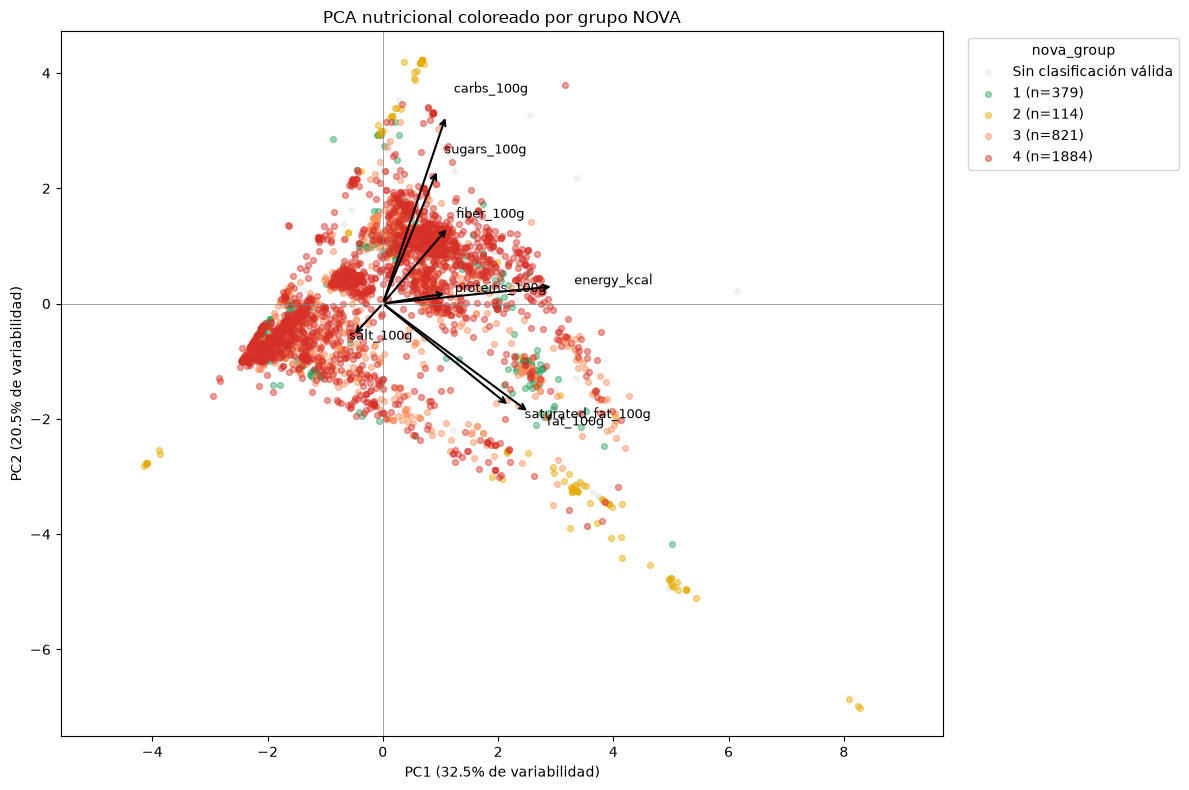

In [117]:
colores_nova = {
    1: "#2ca25f",
    2: "#e6ab02",
    3: "#fc8d59",
    4: "#d73027"
}

graficar_pca_coloreado(
    "nova_group",
    colores_nova,
    "PCA nutricional coloreado por grupo NOVA"
)

Sección 7.3 - Generación de PCA con grupos en base a ecoscore.

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


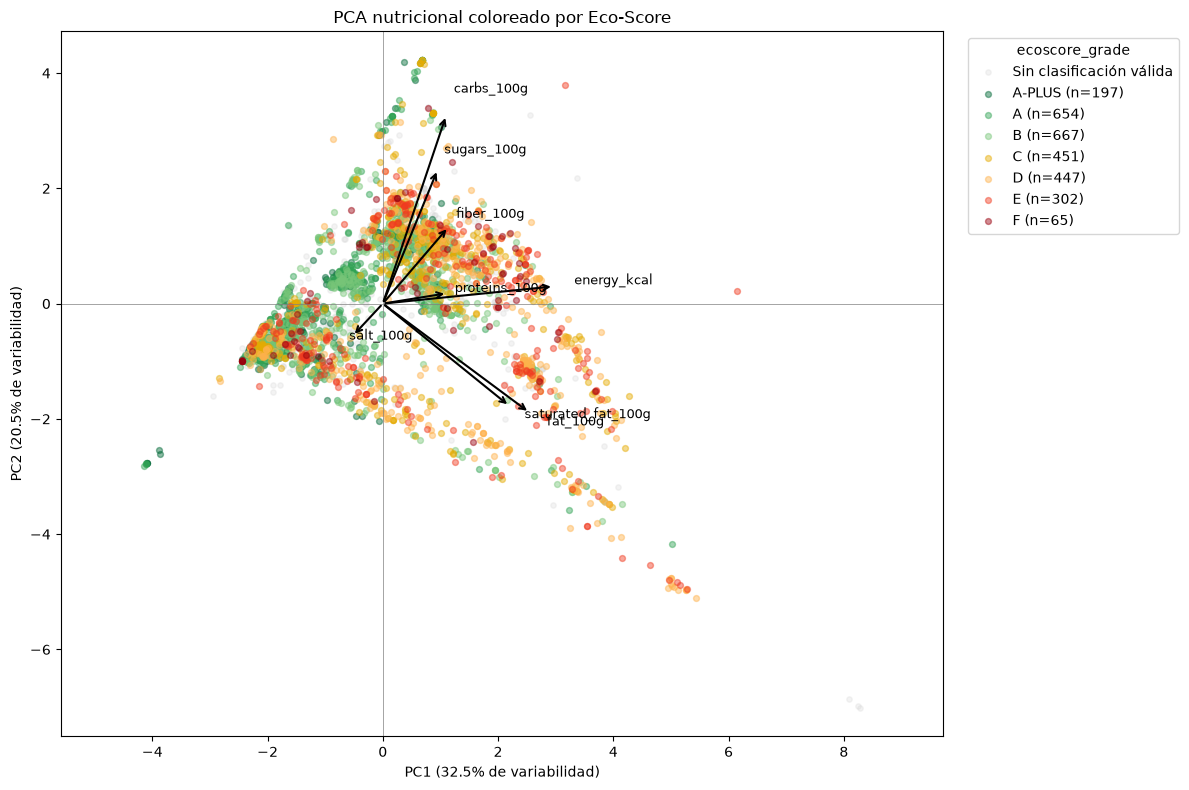

In [118]:
colores_ecoscore = {
    "A-PLUS": "#006837",
    "A": "#31a354",
    "B": "#78c679",
    "C": "#e6ab02",
    "D": "#feb24c",
    "E": "#f03b20",
    "F": "#99000d"
}

graficar_pca_coloreado(
    "ecoscore_grade",
    colores_ecoscore,
    "PCA nutricional coloreado por Eco-Score"
)

### Sección 8 - Hipótesis univariada

Más del 75% de los productos en la población de referencia pertenecen al grupo 3 o 4 nova.


In [119]:
import pandas as pd
from scipy.stats import binomtest

# seleccionamos los productos con clasificación NOVA válida
nova = pd.to_numeric(
    dataset_limpio["nova_group"],
    errors="coerce"
)

nova_valido = nova.loc[nova.isin([1, 2, 3, 4])]

# n: cantidad de productos con NOVA válido en la muestra.
n = len(nova_valido)

# k: cantidad de esos productos que pertenecen a NOVA 3 o 4.
k = int(nova_valido.isin([3, 4]).sum())

if n == 0:
    raise ValueError("No hay productos con clasificación NOVA válida.")

# proporción muestral de productos NOVA 3 o 4.
proporcion_observada = k / n

# H0 - p <= 0.75
# H1 -p > 0.75
resultado = binomtest(
    k=k,
    n=n,
    p=0.75,
    alternative="greater"
)

# intervalo exacto unilateral del 95% [límite inferior, 1]
intervalo = resultado.proportion_ci(
    confidence_level=0.95,
    method="exact"
)

print(f"Productos con NOVA válido: {n}")
print(f"Productos NOVA 3 o 4: {k}")
print(f"Proporción observada: {proporcion_observada:.2%}")
print(
    "Intervalo unilateral de confianza del 95%: "
    f"[{intervalo.low:.2%}, {intervalo.high:.2%}]"
)
print(f"Valor p: {resultado.pvalue:.4g}")

if resultado.pvalue < 0.05:
    print(
        "Se rechaza H0: existe evidencia estadística de que "
        "más del 75% de los productos con NOVA disponible "
        "pertenecen a los grupos 3 o 4."
    )
else:
    print(
        "No se rechaza H0: la evidencia es insuficiente "
        "para concluir que la proporción supera el 75%."
    )

Productos con NOVA válido: 4410
Productos NOVA 3 o 4: 3637
Proporción observada: 82.47%
Intervalo unilateral de confianza del 95%: [81.50%, 100.00%]
Valor p: 6.771e-33
Se rechaza H0: existe evidencia estadística de que más del 75% de los productos con NOVA disponible pertenecen a los grupos 3 o 4.


### Sección 9 - Hipótesis bivariada
Los productos de los grupos NOVA 3 y 4 presentan una mayor proporción de calificaciones Eco-Score E o F que los productos de los grupos NOVA 1 y 2.

In [120]:
import pandas as pd
import numpy as np
from statsmodels.stats.proportion import proportions_ztest

datos = dataset_limpio[["nova_group", "ecoscore_grade"]].copy()

datos["nova_group"] = pd.to_numeric(
    datos["nova_group"],
    errors="coerce"
)

datos["ecoscore_grade"] = (
    datos["ecoscore_grade"]
    .astype("string")
    .str.strip()
    .str.upper()
)

grados_validos = ["A-PLUS", "A", "B", "C", "D", "E", "F"]

clasificacion_valida = (
    datos["nova_group"].isin([1, 2, 3, 4])
    & datos["ecoscore_grade"].isin(grados_validos)
)

datos_validos = datos.loc[clasificacion_valida].copy()

print("Productos incluidos:", len(datos_validos))
print("Productos excluidos:", len(datos) - len(datos_validos))


# separamos nova en dos grupos.
nova_34 = datos_validos.loc[
    datos_validos["nova_group"].isin([3, 4])
]

nova_12 = datos_validos.loc[
    datos_validos["nova_group"].isin([1, 2])
]

# n_34 y n_12: cantidad de productos válidos de cada grupo.
n_34 = len(nova_34)
n_12 = len(nova_12)

# exitos_34 y exitos_12: productos con Eco-Score E o F.
exitos_34 = int(nova_34["ecoscore_grade"].isin(["E", "F"]).sum())
exitos_12 = int(nova_12["ecoscore_grade"].isin(["E", "F"]).sum())

proporcion_34 = exitos_34 / n_34
proporcion_12 = exitos_12 / n_12

resumen = pd.DataFrame({
    "Grupo": ["NOVA 3/4", "NOVA 1/2"],
    "Productos válidos": [n_34, n_12],
    "Eco-Score E/F": [exitos_34, exitos_12],
    "Porcentaje E/F": [
        proporcion_34 * 100,
        proporcion_12 * 100
    ]
})

display(resumen.round(2))


# tabla de contingencia.
tabla = np.array([
    [exitos_34, n_34 - exitos_34],
    [exitos_12, n_12 - exitos_12]
])

display(pd.DataFrame(
    tabla,
    index=["NOVA 3/4", "NOVA 1/2"],
    columns=["Eco-Score E/F", "Otros grados válidos"]
))

estadistico, valor_p = proportions_ztest(
    count=[exitos_34, exitos_12],
    nobs=[n_34, n_12],
    alternative="larger"
)

print(f"Estadístico Z: {estadistico:.4f}")

# Imprimimos/ interpretamos el resultado.
alpha = 0.05

print(f"Valor p: {valor_p:.6g}")

if valor_p < alpha:
    print(
        "Se rechaza H0. Existe evidencia estadística de una "
        "mayor proporción de Eco-Score E/F en NOVA 3/4 "
        "que en NOVA 1/2."
    )
else:
    print(
        "No se rechaza H0. No hay evidencia estadística suficiente "
        "para concluir que la proporción de Eco-Score E/F "
        "sea mayor en NOVA 3/4."
    )

Productos incluidos: 3580
Productos excluidos: 1260


,Grupo,Productos válidos,Eco-Score E/F,Porcentaje E/F
0,NOVA 3/4,2974,451,15.16
1,NOVA 1/2,606,88,14.52


,Eco-Score E/F,Otros grados válidos
NOVA 3/4,451,2523
NOVA 1/2,88,518


Estadístico Z: 0.4036
Valor p: 0.343249
No se rechaza H0. No hay evidencia estadística suficiente para concluir que la proporción de Eco-Score E/F sea mayor en NOVA 3/4.


### Sección 10 - Hipótesis multivariada
Los productos NOVA 4 tienen, en promedio, más azúcar que los productos NOVA 1/2/3, a igual categoría alimentaria.

Productos incluidos: 3640
Productos excluidos: 1200
                            OLS Regression Results                            
Dep. Variable:            sugars_100g   R-squared:                       0.443
Model:                            OLS   Adj. R-squared:                  0.442
Method:                 Least Squares   F-statistic:                     289.2
Date:                Tue, 10 Nov 2026   Prob (F-statistic):               0.00
Time:                        01:08:35   Log-Likelihood:                -14588.
No. Observations:                3640   AIC:                         2.920e+04
Df Residuals:                    3629   BIC:                         2.927e+04
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                                      coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------

,Modelo,Coef. NOVA 4 (g/100g),R²,AIC,BIC
0,Sin considerar categoría,6.589,0.033,31192,31204
1,Considerando categoría,2.210,0.443,29198,29267


shapiro-wilk de los residuos: p = 9.203e-58


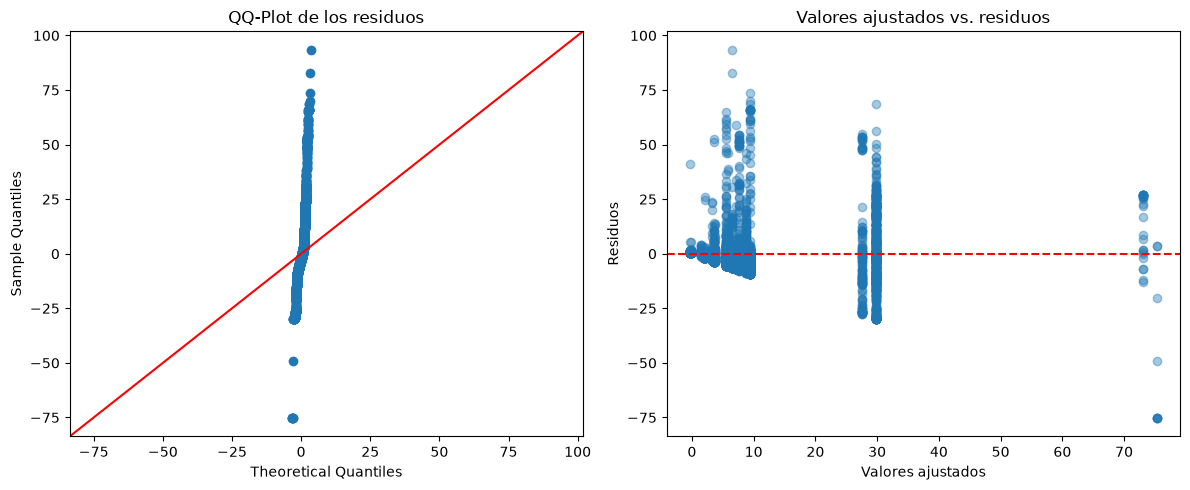

Coeficiente de NOVA 4: 2.210 g por 100 g (IC 95%: [1.283, 3.137])
Valor p (unilateral): 1.526e-06
Los residuos no son normales: el coeficiente y su p-valor no se pueden asumir válidos


In [121]:
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy.stats import shapiro

datos = dataset_limpio[["nova_group", "categoria_grafico", "sugars_100g"]].copy()

datos["nova_group"] = pd.to_numeric(datos["nova_group"], errors="coerce")
datos["sugars_100g"] = pd.to_numeric(datos["sugars_100g"], errors="coerce")

clasificacion_valida = (
    datos["nova_group"].isin([1, 2, 3, 4])
    & datos["sugars_100g"].notna()
    & ~datos["categoria_grafico"].isin(["Sin clasificar", "Otros"])
)

print("Productos incluidos:", clasificacion_valida.sum())
print("Productos excluidos:", (~clasificacion_valida).sum())

datos = datos.loc[clasificacion_valida].copy()

# 1 si el producto es NOVA 4, 0 si es NOVA 1/2/3
datos["nova4"] = (datos["nova_group"] == 4).astype(float)

y = datos["sugars_100g"]

# sin considerar la categoría
X_simple = sm.add_constant(datos[["nova4"]])
modelo_simple = sm.OLS(y, X_simple).fit()

# considerando la categoria (con dummies hacemos el encoding)
X = pd.get_dummies(datos["categoria_grafico"], drop_first=True, dtype=float)
X["nova4"] = datos["nova4"]
X = sm.add_constant(X)
modelo = sm.OLS(y, X).fit()

print(modelo.summary())

print()

# comparacion de modelos
resultados = []
for nombre, m in [("Sin considerar categoría", modelo_simple), ("Considerando categoría", modelo)]:
    resultados.append({
        "Modelo": nombre,
        "Coef. NOVA 4 (g/100g)": round(m.params['nova4'], 3),
        "R²": round(m.rsquared, 3),
        "AIC": int(m.aic),
        "BIC": int(m.bic)
    })
tabla_comparativa = pd.DataFrame(resultados)
display(tabla_comparativa)

alpha = 0.05

# se testea normalidad por Shapiro-Wilk)
_, p_shapiro = shapiro(modelo.resid)
print(f"shapiro-wilk de los residuos: p = {p_shapiro:.4g}")

# QQ-plot y valores ajustados vs. residuos
fig, ejes = plt.subplots(1, 2, figsize=(12, 5))

sm.qqplot(modelo.resid, line="45", ax=ejes[0])
ejes[0].set_title("QQ-Plot de los residuos")

ejes[1].scatter(modelo.fittedvalues, modelo.resid, alpha=0.4)
ejes[1].axhline(0, color="red", linestyle="--")
ejes[1].set_xlabel("Valores ajustados")
ejes[1].set_ylabel("Residuos")
ejes[1].set_title("Valores ajustados vs. residuos")

plt.tight_layout()
plt.show()

beta = modelo.params["nova4"]
intervalo = modelo.conf_int().loc["nova4"]

# Como H1 es unilateral (beta > 0) se ajusta según el signo
p_bilateral = modelo.pvalues["nova4"]
valor_p = p_bilateral / 2 if beta > 0 else 1 - p_bilateral / 2

print(f"Coeficiente de NOVA 4: {beta:.3f} g por 100 g (IC 95%: [{intervalo.iloc[0]:.3f}, {intervalo.iloc[1]:.3f}])")
print(f"Valor p (unilateral): {valor_p:.4g}")

if p_shapiro <= alpha:
    print(
        "Los residuos no son normales: el coeficiente y su p-valor no se pueden asumir válidos"
    )
elif valor_p < alpha:
    print(
        "Se rechaza H0. Existe evidencia estadística de que, a igual categoría, "
        "los productos NOVA 4 tienen en promedio más azúcar que los NOVA 1/2/3."
    )
else:
    print(
        "No se rechaza H0. No hay evidencia estadística suficiente para concluir que, "
        "a igual categoría, los productos NOVA 4 tengan en promedio más azúcar."
    )

### Sección 11 - Hipótesis univariada

La proporción de productos catalogados como "altos en grasas saturadas" (más de 5 g de grasa saturada por cada 100 g de producto) en la población de referencia es superior al 25%.

In [122]:
import pandas as pd
from scipy.stats import binomtest

# Seleccionar productos con valores válidos de grasas saturadas.
grasas_saturadas = pd.to_numeric(
    dataset_limpio["saturated_fat_100g"],
    errors="coerce"
)
# Eliminar valores faltantes
grasas_validas = grasas_saturadas.dropna()

# n: cantidad de productos en la muestra que tienen un valor válido para grasas saturadas.
n = len(grasas_validas)

# k: cantidad de esos productos que cumplen la condición de "altos en grasas" (> 5g).
k = int((grasas_validas > 5).sum())

if n == 0:
    raise ValueError("No hay productos con datos de grasas saturadas válidos.")

proporcion_observada = k / n

# H0: p <= 0.25
# H1: p > 0.25 (La proporción poblacional es estrictamente mayor al 25%)
resultado = binomtest(
    k=k,
    n=n,
    p=0.25,
    alternative="greater"
)

# Intervalo exacto unilateral del 95%: [límite inferior, 1].
intervalo = resultado.proportion_ci(
    confidence_level=0.95,
    method="exact"
)

print(f"Productos con datos de grasas saturadas válidos: {n}")
print(f"Productos altos en grasas saturadas (> 5g/100g): {k}")
print(f"Proporción observada: {proporcion_observada:.2%}")
print(
    "Intervalo unilateral de confianza del 95%: "
    f"[{intervalo.low:.2%}, {intervalo.high:.2%}]"
)
print(f"Valor p: {resultado.pvalue:.4g}")

# p-value = 0.05
if resultado.pvalue < 0.05:
    print(
        "Se rechaza H0: existe evidencia estadística de que "
        "más del 25% de los productos de la población de referencia "
        "son altos en grasas saturadas."
    )
else:
    print(
        "No se rechaza H0: la evidencia es insuficiente "
        "para concluir que la proporción supera el 25%."
    )

Productos con datos de grasas saturadas válidos: 4513
Productos altos en grasas saturadas (> 5g/100g): 1381
Proporción observada: 30.60%
Intervalo unilateral de confianza del 95%: [29.47%, 100.00%]
Valor p: 1.11e-17
Se rechaza H0: existe evidencia estadística de que más del 25% de los productos de la población de referencia son altos en grasas saturadas.


### Sección 12 - Hipótesis bivariada
El grado de procesamiento industrial de un alimento está asociado con la calificación nutricional Nutri-Score que recibe, de manera que los productos más procesados presentan calificaciones más desfavorables.

In [123]:
import pandas as pd
import numpy as np
from statsmodels.stats.proportion import proportions_ztest

datos = dataset_limpio[["nova_group", "nutriscore_grade"]].copy()

datos["nova_group"] = pd.to_numeric(
    datos["nova_group"],
    errors="coerce"
)

datos["nutriscore_grade"] = (
    datos["nutriscore_grade"]
    .astype("string")
    .str.strip()
    .str.upper()
)

grados_validos = ["A", "B", "C", "D", "E"] # Nutri-Score va de la A a la E

clasificacion_valida = (
    datos["nova_group"].isin([1, 2, 3, 4])
    & datos["nutriscore_grade"].isin(grados_validos)
)

datos_validos = datos.loc[clasificacion_valida].copy()

print("Productos incluidos:", len(datos_validos))
print("Productos excluidos:", len(datos) - len(datos_validos))


# Separamos nova en dos grupos
nova_34 = datos_validos.loc[
    datos_validos["nova_group"].isin([3, 4])
]
nova_12 = datos_validos.loc[
    datos_validos["nova_group"].isin([1, 2])
]

# n_34 y n_12: cantidad total de productos válidos en cada grupo.
n_34 = len(nova_34)
n_12 = len(nova_12)

# exitos_34 y exitos_12: productos con Nutri-Score D o E.
exitos_34 = int(nova_34["nutriscore_grade"].isin(["D", "E"]).sum())
exitos_12 = int(nova_12["nutriscore_grade"].isin(["D", "E"]).sum())

proporcion_34 = exitos_34 / n_34
proporcion_12 = exitos_12 / n_12

resumen = pd.DataFrame({
    "Grupo": ["NOVA 3/4 (Más procesado)", "NOVA 1/2 (Menos procesado)"],
    "Productos válidos": [n_34, n_12],
    "Nutri-Score D/E": [exitos_34, exitos_12],
    "Porcentaje D/E": [
        proporcion_34 * 100,
        proporcion_12 * 100
    ]
})

display(resumen.round(2))


# tabla de contingencia.
tabla = np.array([
    [exitos_34, n_34 - exitos_34],
    [exitos_12, n_12 - exitos_12]
])

display(pd.DataFrame(
    tabla,
    index=["NOVA 3/4", "NOVA 1/2"],
    columns=["Nutri-Score D/E", "Nutri-Score A/B/C"]
))

# H0 - La proporción de D/E en NOVA 3/4 es <= que en NOVA 1/2
# H1 -La proporción de D/E en NOVA 3/4 es mayor
estadistico, valor_p = proportions_ztest(
    count=[exitos_34, exitos_12],
    nobs=[n_34, n_12],
    alternative="larger"
)

print(f"Estadístico Z: {estadistico:.4f}")
print(f"Valor p: {valor_p:.6g}")

alpha = 0.05

if valor_p < alpha:
    print(
        "Se rechaza H0. Existe evidencia estadística de una "
        "mayor proporción de calificaciones Nutri-Score desfavorables (D/E) "
        "en alimentos ultraprocesados (NOVA 3/4) que en alimentos no procesados "
        "o con poco procesamiento (NOVA 1/2)."
    )
else:
    print(
        "No se rechaza H0. No hay evidencia estadística suficiente "
        "para concluir que los productos más procesados (NOVA 3/4) "
        "presenten una mayor proporción de calificaciones Nutri-Score D/E."
    )

Productos incluidos: 4075
Productos excluidos: 765


,Grupo,Productos válidos,Nutri-Score D/E,Porcentaje D/E
0,NOVA 3/4 (Más procesado),3396,1584,46.64
1,NOVA 1/2 (Menos procesado),679,139,20.47


,Nutri-Score D/E,Nutri-Score A/B/C
NOVA 3/4,1584,1812
NOVA 1/2,139,540


Estadístico Z: 12.6025
Valor p: 1.02331e-36
Se rechaza H0. Existe evidencia estadística de una mayor proporción de calificaciones Nutri-Score desfavorables (D/E) en alimentos ultraprocesados (NOVA 3/4) que en alimentos no procesados o con poco procesamiento (NOVA 1/2).


### Sección 13 - Hipótesis multivariada
El grado de procesamiento industrial (NOVA), la categoría del producto y la cantidad de alérgenos declarados explican conjuntamente la probabilidad de que un producto reciba una calificación Nutri-Score desfavorable (D/E), sin utilizar directamente su composición nutricional.


In [124]:
import pandas as pd
import statsmodels.api as sm

datos = dataset_limpio[["nova_group", "categoria_grafico", "allergens", "nutriscore_grade"]].copy()

datos["nova_group"] = pd.to_numeric(datos["nova_group"], errors="coerce")

datos["nutriscore_grade"] = (
    datos["nutriscore_grade"]
    .astype("string")
    .str.strip()
    .str.upper()
)

# Tomamos los alergenos nulos como 0 y contamos la cantidad que tienen
datos["cantidad_alergenos"] = datos["allergens"].fillna("").apply(
    lambda texto: len({e.strip().casefold() for e in texto.split(",") if e.strip()})
)

# Controlamos que sean valores validos
clasificacion_valida = (
    datos["nova_group"].isin([1, 2, 3, 4])
    & datos["nutriscore_grade"].isin(["A", "B", "C", "D", "E"])
    & ~datos["categoria_grafico"].isin(["Sin clasificar", "Otros"])
)

print("Productos incluidos:", clasificacion_valida.sum())
print("Productos excluidos:", (~clasificacion_valida).sum())

datos = datos.loc[clasificacion_valida].copy()
datos["nova"] = datos["nova_group"].astype(int)

# y es 1 si el nutriscore es D o E, 0 si es A, B o C
y = datos["nutriscore_grade"].isin(["D", "E"]).astype(int)

# Transformamos NOVA y categoría con encoding dummies, y la cantidad de alérgenos como número
X = pd.get_dummies(
    datos[["nova", "categoria_grafico"]].astype(str),
    drop_first=True,
    dtype=float
)
X["cantidad_alergenos"] = datos["cantidad_alergenos"].astype(float)

X = sm.add_constant(X)

# Ajustamos la regresión logística (para que de una respuesta binaria)
modelo = sm.Logit(y, X).fit(disp=False)
print(modelo.summary())

# H0 - todos los coeficientes (salvo la constante) son 0, entonces no explican la probabilidad de recibir Nutri-Score D/E
# H1 - hay por lo menos un coeficiente  distinto de 0
# Test LR: modelo completo vs. modelo sin variables explicativas.
alpha = 0.05
valor_p = modelo.llr_pvalue

print(f"Estadístico LR: {modelo.llr:.4f}")
print(f"Grados de libertad: {int(modelo.df_model)}")
print(f"Valor p: {valor_p:.6g}")
print(f"Pseudo R² de McFadden: {modelo.prsquared:.4f}")

if valor_p < alpha:
    print(
        "Se rechaza H0. Existe evidencia estadística de que el grado de "
        "procesamiento (NOVA), la categoría del producto y la cantidad de "
        "alérgenos declarados explican conjuntamente la probabilidad de "
        "recibir un Nutri-Score desfavorable (D/E)."
    )
else:
    print(
        "No se rechaza H0. No hay evidencia estadística suficiente "
        "para concluir que NOVA, la categoría y la cantidad de alérgenos "
        "expliquen conjuntamente la probabilidad de un Nutri-Score D/E."
    )

Productos incluidos: 3549
Productos excluidos: 1291
                           Logit Regression Results                           
Dep. Variable:       nutriscore_grade   No. Observations:                 3549
Model:                          Logit   Df Residuals:                     3535
Method:                           MLE   Df Model:                           13
Date:                Tue, 10 Nov 2026   Pseudo R-squ.:                  0.2803
Time:                        01:08:36   Log-Likelihood:                -1752.1
converged:                       True   LL-Null:                       -2434.5
Covariance Type:            nonrobust   LLR p-value:                6.318e-284
                                                        coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------------------------------
const                                                 1.4539      0.770      1.8